# Lecture 4 notebook: Tracking hidden states with the Kalman filter

Companion to Lecture 4 of *Systematic Trading Notes*. Lecture 2 smoothed prices from the bottom up,
by averaging past bars. This notebook works from the top down: a state-space model says what is hidden
behind prices (a level, a slope, an acceleration), how it moves from bar to bar, and how prices relate
to it; the Kalman filter updates that model with each new bar.

The notebook builds three linear designs (level only; level + slope; level + slope + acceleration),
shows what each design follows regardless of its tuning, profiles what each hidden state captures in
different market conditions, and then covers extensions, the extended and unscented filters, and a
time-varying hedge ratio. Every number quoted in the lecture is produced here.

Variables are named by meaning: *level*, *slope*, *acceleration* (states); *q_level*, *q_slope*,
*q_acceleration* (how much each state may change per bar, the diagonal of $Q$); *r_price* (price noise,
$R$); *uncertainty* ($P$); *gain* ($K$); *surprise* (price minus forecast).

References are listed at the end.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots
from scipy.stats import kurtosis, norm, skew

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "04-tracking-hidden-states" / "figures"
TICKERS = ["SPY", "QQQ", "GLD", "AGG"]

## 1. Data

Adjusted daily OHLC for SPY, QQQ, GLD and AGG from `trading_models.data.ohlc`, sharing the Lecture 3 notebook's
cache. All filters run on log prices, so a slope is a daily log trend (shown annualised, x252).

In [2]:
ohlc = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb12_ohlc_long.csv")
O, H, L, C = (ohlc[f] for f in ("open", "high", "low", "close"))
for t in TICKERS:
    s = C[t].dropna()
    print(f"{t}: {s.index[0].date()} to {s.index[-1].date()}, {len(s)} bars")
qqq = C["QQQ"].dropna()
y_qqq = np.log(qqq.to_numpy())
dates = qqq.index

SPY: 1993-01-29 to 2026-10-09, 8482 bars
QQQ: 1999-03-10 to 2026-10-09, 6940 bars
GLD: 2004-11-18 to 2026-10-09, 5507 bars
AGG: 2003-09-29 to 2026-10-09, 5795 bars


## 2. The linear Kalman filter, with named variables

Each bar the filter **predicts** the hidden state forward, **compares** the forecast with the new
price (the *surprise*), and **corrects** the state by *gain* x *surprise*. The gain is large when the
filter is uncertain about its state relative to the price noise, and small otherwise.

Three designs, all on log price; the transition matrix says how the states move over one bar:

| Design | States | One-bar transition |
|---|---|---|
| Level only | level | level stays where it was |
| Level + slope | level, slope | level moves by the slope |
| Level + slope + acceleration | level, slope, acceleration | level moves by slope + 0.5 x acceleration; slope moves by acceleration |

The optional arguments are used later: `cap` caps extreme surprises (a robust update, section 8),
`r_series` lets the price noise change bar by bar, `damping` lets the slope fade.

In [3]:
def kalman(prices, transition, observe, q_diag, r_price, start_uncertainty=1.0, start_state=None,
           cap=None, r_series=None, full_q=None):
    n = transition.shape[0]
    state = np.zeros(n)
    state[0] = prices[0]
    if start_state is not None:
        state = np.array(start_state, dtype=float)
    uncertainty = np.eye(n) * start_uncertainty
    Q = np.diag(q_diag) if full_q is None else full_q
    T = len(prices)
    out = {k: np.empty(T) for k in ("forecast", "surprise", "z", "gain", "surprise_var")}
    states, sds = np.empty((T, n)), np.empty((T, n))
    z_var = 1.0                                                        # running scale of recent surprises (robust update)
    for t, price in enumerate(prices):
        r = r_price if r_series is None else r_series[t]
        state = transition @ state                                     # predict
        uncertainty = transition @ uncertainty @ transition.T + Q
        forecast = observe @ state
        surprise_var = observe @ uncertainty @ observe + r
        gain = uncertainty @ observe / surprise_var                    # trust in the new price
        surprise = price - forecast                                    # compare
        z = surprise / np.sqrt(surprise_var)
        used = surprise
        if cap is not None:
            limit = cap * np.sqrt(z_var)                                   # cap relative to the recent typical surprise
            if abs(z) > limit:
                used = np.sign(surprise) * limit * np.sqrt(surprise_var)
            z_var = (1 - 1 / 252) * z_var + (1 / 252) * min(z ** 2, limit ** 2)   # updated with past data only
        state = state + gain * used                                    # correct
        uncertainty = uncertainty - np.outer(gain, observe @ uncertainty)
        states[t], sds[t] = state, np.sqrt(np.diag(uncertainty))
        for k, v in (("forecast", forecast), ("surprise", surprise), ("z", z), ("gain", gain[0]),
                     ("surprise_var", surprise_var)):
            out[k][t] = v
    out["states"], out["sd"] = states, sds
    return out


def design(n_states, damping=1.0):
    if n_states == 1:
        return np.array([[1.0]]), np.array([1.0])
    if n_states == 2:
        return np.array([[1.0, 1.0], [0.0, damping]]), np.array([1.0, 0.0])
    return np.array([[1.0, 1.0, 0.5], [0.0, 1.0, 1.0], [0.0, 0.0, 1.0]]), np.array([1.0, 0.0, 0.0])


Q_REL = {1: np.array([1.0]), 2: np.array([1.0, 1e-2]), 3: np.array([1.0, 1e-2, 1e-4])}
NAMES = {1: "Level only", 2: "Level + slope", 3: "Level + slope + acceleration"}


def run(prices, k, r_price, q_scale=1e-4, damping=1.0, **kw):
    F, Hh = design(k, damping)
    return kalman(prices, F, Hh, Q_REL[k] * q_scale, r_price, **kw)


def ema(x, alpha):
    out = np.empty(len(x)); out[0] = x[0]
    for t in range(1, len(x)):
        out[t] = alpha * x[t] + (1 - alpha) * out[t - 1]
    return out

## 2b. One bar at a time: every matrix and vector

The level + slope design (LS) on QQQ log closes from the first bar, with the long-horizon settings of
Lecture 4b, section 6: price noise $r = 10^{-4}$ (a 1% daily price noise), $q_\ell = 0.1\,r$ and
$q_s = 5.3\times10^{-6}\,r$ (the slope remembers like EMA(252)). Start: $x_0 = (\text{first price}, 0)$ and
$P_0 = I$, diffuse relative to $r$. Notation and step numbers as in Lecture 4b, Table 1.3: $x_{t|t-1}$ and $P_{t|t-1}$ before
the bar is seen, $e_t$ the surprise, $S_t$ its variance, $K_t$ the gain, $x_{t|t}$ and $P_{t|t}$ after.

In [4]:
F_ls, H_ls = design(2)
r_walk = 1e-4
Q_walk = np.diag([0.1 * r_walk, 5.3e-6 * r_walk])
x_est, P_est = np.array([y_qqq[0], 0.0]), np.eye(2)
np.set_printoptions(precision=6, suppress=False)
print("Model:  F =", F_ls.tolist(), "  H =", H_ls.tolist(), "  Q = diag", np.diag(Q_walk).tolist(), "  r =", r_walk)
print("Start:  x_0 =", x_est.round(6).tolist(), "  P_0 = I\n")
walk_rows = []
for t in range(600):
    x_pred = F_ls @ x_est                                   # step 1: x_{t|t-1}
    P_pred = F_ls @ P_est @ F_ls.T + Q_walk                 # step 2: P_{t|t-1}
    y_hat = H_ls @ x_pred                                   # step 3: forecast of the price
    S_t = H_ls @ P_pred @ H_ls + r_walk                     # step 4: expected variance of the surprise
    K_t = P_pred @ H_ls / S_t                               # step 5: gain
    e_t = y_qqq[t] - y_hat                                  # step 6: surprise (today's price enters here)
    x_est = x_pred + K_t * e_t                              # step 7: x_{t|t}
    P_est = P_pred - np.outer(K_t, H_ls @ P_pred)           # step 8: P_{t|t}
    if t < 3:
        print(f"--- bar {t + 1} ({dates[t].date()}), y_t = log price = {y_qqq[t]:.6f}")
        print("  x_{t|t-1} =", x_pred.round(6).tolist(), "   P_{t|t-1} =", P_pred.round(8).tolist())
        print(f"  e_t = {e_t:.6f}   S_t = {S_t:.6f}   K_t =", K_t.round(6).tolist())
        print("  x_{t|t}   =", x_est.round(6).tolist(), "   P_{t|t}   =", P_est.round(8).tolist(), "\n")
    if t + 1 in (1, 2, 3, 10, 100, 500):
        walk_rows.append({"bar": t + 1, "date": dates[t].date(), "price": qqq.iloc[t], "forecast": np.exp(y_hat),
                          "surprise e_t (%)": 100 * e_t, "K level": K_t[0], "K slope": K_t[1], "level": np.exp(x_est[0]),
                          "slope (% a year)": 25200 * x_est[1], "sd of slope (% a year)": 25200 * np.sqrt(P_est[1, 1])})
display(pd.DataFrame(walk_rows).set_index("bar").round(3))

Model:  F = [[1.0, 1.0], [0.0, 1.0]]   H = [1.0, 0.0]   Q = diag [1e-05, 5.3e-10]   r = 0.0001
Start:  x_0 = [3.760788, 0.0]   P_0 = I

--- bar 1 (1999-03-10), y_t = log price = 3.760788
  x_{t|t-1} = [3.760788, 0.0]    P_{t|t-1} = [[2.00001, 1.0], [1.0, 1.0]]
  e_t = 0.000000   S_t = 2.000110   K_t = [0.99995, 0.499973]
  x_{t|t}   = [3.760788, 0.0]    P_{t|t}   = [[0.0001, 5e-05], [5e-05, 0.5000275]] 

--- bar 2 (1999-03-11), y_t = log price = 3.765671
  x_{t|t-1} = [3.760788, 0.0]    P_{t|t-1} = [[0.50023749, 0.5000775], [0.5000775, 0.5000275]]
  e_t = 0.004884   S_t = 0.500337   K_t = [0.9998, 0.99948]
  x_{t|t}   = [3.765671, 0.004881]    P_{t|t}   = [[9.998e-05, 9.995e-05], [9.995e-05, 0.00020986]] 

--- bar 3 (1999-03-12), y_t = log price = 3.741009
  x_{t|t-1} = [3.770552, 0.004881]    P_{t|t-1} = [[0.00051974, 0.00030981], [0.00030981, 0.00020986]]
  e_t = -0.029542   S_t = 0.000620   K_t = [0.838641, 0.499904]
  x_{t|t}   = [3.745776, -0.009887]    P_{t|t}   = [[8.386e-05, 4.

,date,price,forecast,surprise e_t (%),K level,K slope,level,slope (% a year),sd of slope (% a year)
bar,,,,,,,,,
1,1999-03-10,42.982,42.982,0.000,1.000,0.500,42.982,0.000,17819.581
2,1999-03-11,43.193,42.982,0.488,1.000,0.999,43.193,123.003,365.061
3,1999-03-12,42.140,43.404,-2.954,0.839,0.500,42.342,-249.160,186.865
10,1999-03-23,41.088,43.281,-5.199,0.416,0.059,42.356,-59.609,39.259
100,1999-07-30,47.638,48.599,-1.997,0.279,0.003,48.329,29.881,8.893
500,2001-03-01,41.078,42.112,-2.486,0.275,0.002,41.824,-71.413,6.882


**The start on made-up prices (Lecture 4b, Tables 1.4 and 1.5).** The three-state design on the prices
50, 52, 55, 57, with $q = (10^{-4}, 10^{-6}, 10^{-8})$, $r = 1$, $x_0 = (50, 0, 0)$ and $P_0 = 10^6 I$. Each row
shows the steps of Lecture 4b, Table 1.3. The gains are then run forward without any prices, to find the bar
from which every gain stays within 1% of its final value.

In [5]:
F3t, H3t = design(3)
Q_toy, r_toy = np.diag([1e-4, 1e-6, 1e-8]), 1.0
x_t, P_t = np.array([50.0, 0.0, 0.0]), np.eye(3) * 1e6
rows = {}
for bar, price in enumerate([50.0, 52.0, 55.0, 57.0], start=1):
    x_pred = F3t @ x_t                                      # step 1
    P_pred = F3t @ P_t @ F3t.T + Q_toy                      # step 2
    y_hat = H3t @ x_pred                                    # step 3
    S_toy = H3t @ P_pred @ H3t + r_toy                      # step 4
    K_toy = P_pred @ H3t / S_toy                            # step 5
    e_toy = price - y_hat                                   # step 6
    x_t = x_pred + K_toy * e_toy                            # step 7
    P_t = P_pred - np.outer(K_toy, H3t @ P_pred)            # step 8
    rows[bar] = {"price": price, "predicted state (1)": np.round(x_pred, 2).tolist(), "predicted sd (2)": np.round(np.sqrt(np.diag(P_pred)), 1).tolist(), "forecast (3)": y_hat, "sqrt S (4)": np.sqrt(S_toy),
                 "gains (5)": np.round(K_toy, 3).tolist(), "surprise (6)": e_toy,
                 "level/slope/acc (7)": np.round(x_t, 3).tolist(), "sd (8)": np.round(np.sqrt(np.diag(P_t)), 3).tolist()}
display(pd.DataFrame(rows).T)

P_g, gains = np.eye(3) * 1e6, []
for _ in range(5000):                                     # gains need no prices
    P_pred = F3t @ P_g @ F3t.T + Q_toy
    K_g = P_pred @ H3t / (H3t @ P_pred @ H3t + r_toy)
    P_g = P_pred - np.outer(K_g, H3t @ P_pred)
    gains.append(K_g)
gains = np.array(gains)
print(pd.DataFrame(gains[[3, 9, 49, 99, 199]], index=[4, 10, 50, 100, 200], columns=["level", "slope", "acceleration"]).round(4))
settled = max(int(np.where(np.abs(gains[:, i] - gains[-1, i]) > 0.01 * gains[-1, i])[0][-1]) + 2 for i in range(3))
print(f"every gain within 1% of its final value from bar {settled}")

,price,predicted state (1),predicted sd (2),forecast (3),sqrt S (4),gains (5),surprise (6),level/slope/acc (7),sd (8)
1,50.0,"[50.0, 0.0, 0.0]","[1500.0, 1414.2, 1000.0]",50.0,1500.000333,"[1.0, 0.667, 0.222]",0.0,"[50.0, 0.0, 0.0]","[1.0, 1000.0, 942.809]"
2,52.0,"[50.0, 0.0, 0.0]","[1374.4, 1795.1, 942.8]",50.0,1374.370056,"[1.0, 1.294, 0.588]",2.0,"[52.0, 2.588, 1.176]","[1.0, 242.543, 485.072]"
3,55.0,"[55.18, 3.76, 1.18]","[485.1, 727.6, 485.1]",55.176464,485.082614,"[1.0, 1.5, 1.0]",-0.176464,"[55.0, 3.5, 1.0]","[1.0, 2.55, 2.449]"
4,57.0,"[59.0, 4.5, 1.0]","[4.4, 4.9, 2.4]",59.000014,4.472127,"[0.95, 1.05, 0.5]",-2.000014,"[57.1, 2.4, 0.0]","[0.975, 1.565, 1.0]"


      level   slope  acceleration
4    0.9500  1.0500        0.5000
10   0.6182  0.2591        0.0455
50   0.1671  0.0136        0.0005
100  0.0966  0.0046        0.0001
200  0.0908  0.0043        0.0001
every gain within 1% of its final value from bar 121


## 2c. Lecture 4b charts: what can be read from the filter

The quantities of Lecture 4b, Table 2.4, on QQQ, with memories suited to longer-term charts:

- **Level + slope design (LS):** the level reacts to each surprise like EMA(15) (steady gain $2/16$), and the
  slope's weights on past prices reach back as far as those of EMA(90) (to 0.1% of their total weight).
  Used for the level, the bands, the slope, the stretch and the surprises.
- **Three-state design (LSA):** same $q_\ell$ and $q_s$, with $q_a$ chosen so that the acceleration's weights
  reach back as far as those of EMA(45). Used for the acceleration only: in one three-state filter the slope
  cannot keep a longer memory than the acceleration, so this filter's slope becomes faster.

Price noise $r = 10^{-4}$; diffuse start on the first bar of QQQ.

LS:  q_level = 0.01293 r, q_slope = 6.05e-06 r; level gain 0.125; slope horizon 311 bars (EMA(90): 311)
LSA: q_acc = 2.99e-07 r; horizons level / slope / acceleration 147 / 156 / 156 bars (EMA(45): 156)
calibrated price noise r = 0.000329 (a daily price noise of 1.81%)


steady sd of the level: 0.64% ; steady sqrt(S): 1.94%


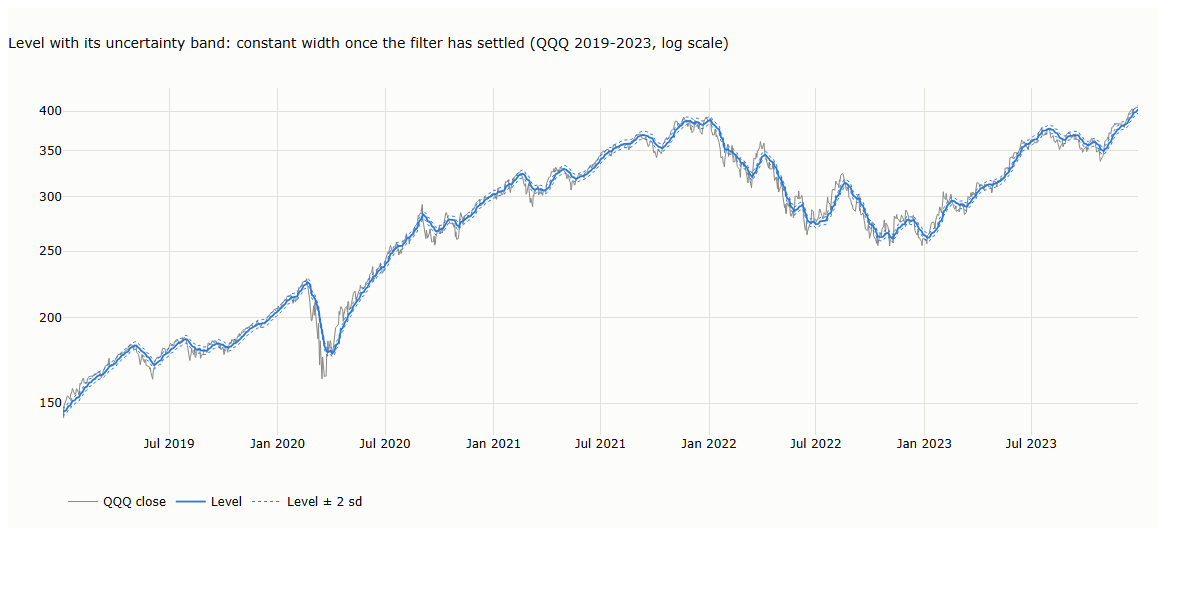

In [6]:
def steady_weights_k(q_rel, n=8000):
    k = len(q_rel); F_k, H_k = design(k); Q_k = np.diag(q_rel); P_k = np.eye(k)
    for _ in range(400000):
        Pp = F_k @ P_k @ F_k.T + Q_k; K_k = Pp @ H_k / (H_k @ Pp @ H_k + 1.0); Pn = Pp - np.outer(K_k, H_k @ Pp)
        if np.allclose(Pn, P_k, rtol=1e-12, atol=0): break
        P_k = Pn
    A_k = (np.eye(k) - np.outer(K_k, H_k)) @ F_k
    W, v = np.empty((n, k)), K_k.copy()
    for j in range(n):
        W[j] = v; v = A_k @ v
    return K_k, W


def tail_horizon(w):
    tail = np.cumsum(np.abs(w)[::-1])[::-1] / np.abs(w).sum()
    return int(np.argmax(tail < 1e-3))


def bisect(f, target, lo, hi, increasing):
    for _ in range(70):
        m = np.sqrt(lo * hi)
        lo, hi = (m, hi) if (f(m) < target) == increasing else (lo, m)
    return m


ema_horizon = lambda N: int(np.ceil(np.log(1e-3) / np.log(1 - 2 / (N + 1))))
ql_rel = 0.05
for _ in range(6):                      # alternate: slope memory = EMA(90), level gain = 2/16
    qs_rel = bisect(lambda q: tail_horizon(steady_weights_k([ql_rel, q])[1][:, 1]), ema_horizon(90), 1e-14, 1e-1, increasing=False)
    ql_rel = bisect(lambda q: steady_weights_k([q, qs_rel])[0][0], 2 / 16, 1e-6, 10, increasing=True)
qa_rel = bisect(lambda q: tail_horizon(steady_weights_k([ql_rel, qs_rel, q])[1][:, 2]), ema_horizon(45), 1e-16, 1e-2, increasing=False)
K2s, W2s = steady_weights_k([ql_rel, qs_rel]); K3s, W3s = steady_weights_k([ql_rel, qs_rel, qa_rel])
print(f"LS:  q_level = {ql_rel:.4g} r, q_slope = {qs_rel:.3g} r; level gain {K2s[0]:.3f}; slope horizon {tail_horizon(W2s[:, 1])} bars (EMA(90): {ema_horizon(90)})")
print(f"LSA: q_acc = {qa_rel:.3g} r; horizons level / slope / acceleration {tail_horizon(W3s[:, 0])} / {tail_horizon(W3s[:, 1])} / {tail_horizon(W3s[:, 2])} bars (EMA(45): {ema_horizon(45)})")

# The ratios fix the estimates; the scale of r fixes the uncertainty. Calibrate the scale so that the normalised
# surprises have variance 1 over 2014-2018, before the charted period (no look-ahead).
r_b = 1e-4
cal = (dates >= "2014-01-01") & (dates <= "2018-12-31")
z_trial = kalman(y_qqq, *design(2), np.array([ql_rel, qs_rel]) * r_b, r_b, start_uncertainty=1.0)["z"]
r_b *= np.mean(z_trial[cal] ** 2)
print(f"calibrated price noise r = {r_b:.3g} (a daily price noise of {100 * np.sqrt(r_b):.2f}%)")
LS_b = kalman(y_qqq, *design(2), np.array([ql_rel, qs_rel]) * r_b, r_b, start_uncertainty=1.0)
LSA_b = kalman(y_qqq, *design(3), np.array([ql_rel, qs_rel, qa_rel]) * r_b, r_b, start_uncertainty=1.0)
lvl, sl = LS_b["states"][:, 0], LS_b["states"][:, 1]
sd_lvl, sd_sl = LS_b["sd"][:, 0], LS_b["sd"][:, 1]
acc, sd_acc = LSA_b["states"][:, 2], LSA_b["sd"][:, 2]
z_b = LS_b["z"]
px = pd.Series(qqq.to_numpy(), dates)
win = (dates >= "2019-01-01") & (dates <= "2023-12-31")
print(f"steady sd of the level: {100 * sd_lvl[-1]:.2f}% ; steady sqrt(S): {100 * np.sqrt(LS_b['surprise_var'][-1]):.2f}%")

# C.1 level with its band
fig = go.Figure()
d = dates[win]
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED))
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.8, color=SERIES[0]))
fig.add_scatter(x=d, y=np.exp(lvl[win] + 2 * sd_lvl[win]), name="Level ± 2 sd", mode="lines", line=dict(width=1, color=SERIES[0], dash="dot"))
fig.add_scatter(x=d, y=np.exp(lvl[win] - 2 * sd_lvl[win]), showlegend=False, mode="lines", line=dict(width=1, color=SERIES[0], dash="dot"))
fig.update_layout(title="Level with its uncertainty band: constant width once the filter has settled (QQQ 2019-2023, log scale)",
                  yaxis=dict(type="log"), height=520, width=1150, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "b_c01_level_bands", FIG)
fig

2019-2023: slope more than 2 sd above zero on 59% of days, below on 17%


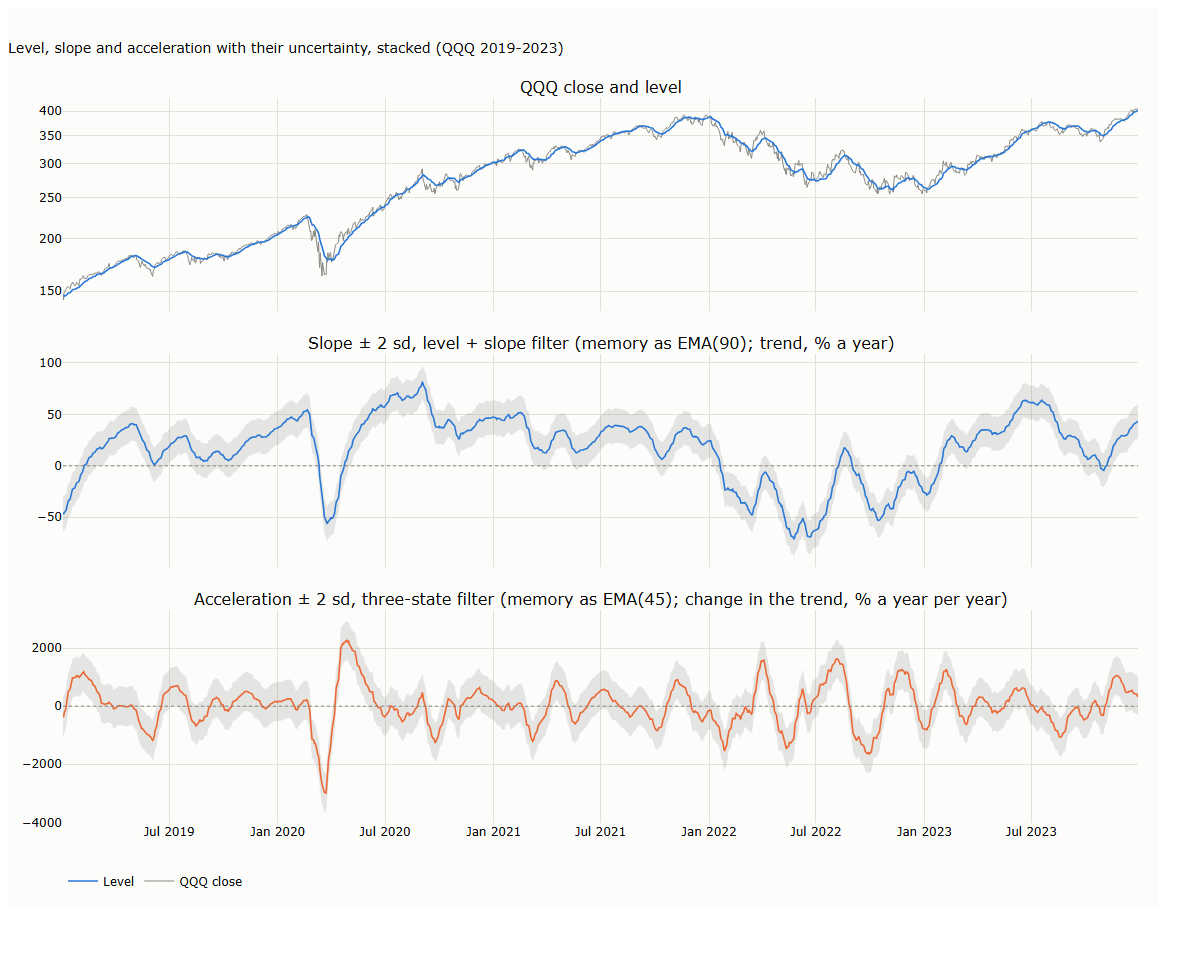

In [7]:
# C.2 price, slope and acceleration, stacked
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                    subplot_titles=("QQQ close and level", "Slope ± 2 sd, level + slope filter (memory as EMA(90); trend, % a year)", "Acceleration ± 2 sd, three-state filter (memory as EMA(45); change in the trend, % a year per year)"))
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.6, color=SERIES[0]), row=1, col=1)
for row, (v, sdv, scale, col) in ((2, (sl, sd_sl, 25200, SERIES[0])), (3, (acc, sd_acc, 25200 * 252, SERIES[1]))):
    fig.add_scatter(x=d, y=scale * (v + 2 * sdv)[win], showlegend=False, mode="lines", line=dict(width=0), row=row, col=1)
    fig.add_scatter(x=d, y=scale * (v - 2 * sdv)[win], showlegend=False, mode="lines", line=dict(width=0), fill="tonexty",
                    fillcolor="rgba(120,120,120,0.18)", row=row, col=1)
    fig.add_scatter(x=d, y=scale * v[win], showlegend=False, mode="lines", line=dict(width=1.6, color=col), row=row, col=1)
    fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=row, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_layout(title="Level, slope and acceleration with their uncertainty, stacked (QQQ 2019-2023)", height=900, width=1150,
                  margin=dict(t=90, b=60), legend=dict(orientation="h", y=-0.06, x=0))
save_figure(fig, "b_c02_slope_acceleration", FIG)
pos = sl[win] > 2 * sd_sl[win]; neg = sl[win] < -2 * sd_sl[win]
print(f"2019-2023: slope more than 2 sd above zero on {100 * pos.mean():.0f}% of days, below on {100 * neg.mean():.0f}%")
fig

stretch 2019-2023: 5th / 95th percentile -4.4% / 4.0%; extremes -16.8% / 9.3%


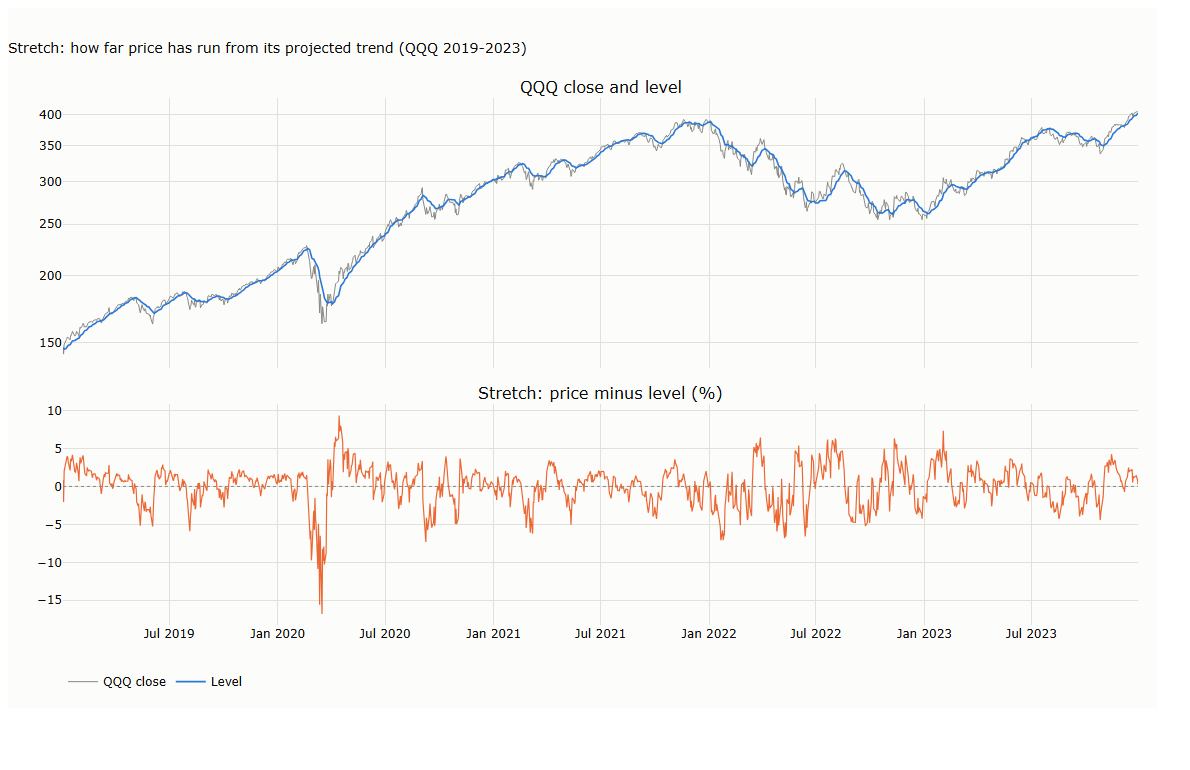

In [8]:
# C.3 stretch
stretch = 100 * (y_qqq - lvl)
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.07, row_heights=[0.55, 0.45],
                    subplot_titles=("QQQ close and level", "Stretch: price minus level (%)"))
fig.add_scatter(x=d, y=px[win], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
fig.add_scatter(x=d, y=np.exp(lvl[win]), name="Level", mode="lines", line=dict(width=1.6, color=SERIES[0]), row=1, col=1)
fig.add_scatter(x=d, y=stretch[win], showlegend=False, mode="lines", line=dict(width=1.2, color=SERIES[1]), row=2, col=1)
fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=2, col=1)
fig.update_yaxes(type="log", row=1, col=1)
fig.update_layout(title="Stretch: how far price has run from its projected trend (QQQ 2019-2023)", height=700, width=1150,
                  margin=dict(t=90, b=60), legend=dict(orientation="h", y=-0.08, x=0))
save_figure(fig, "b_c03_stretch", FIG)
print(f"stretch 2019-2023: 5th / 95th percentile {np.percentile(stretch[win], 5):.1f}% / {np.percentile(stretch[win], 95):.1f}%; extremes {stretch[win].min():.1f}% / {stretch[win].max():.1f}%")
fig

share of days beyond ±3: 6.46% (normal: 0.27%); standard deviation of z: 1.60; 2014-2018: 1.00
days beyond ±3 by year (top 6): {2001: 109, 2000: 67, 2002: 61, 2008: 36, 2022: 32, 2020: 31}


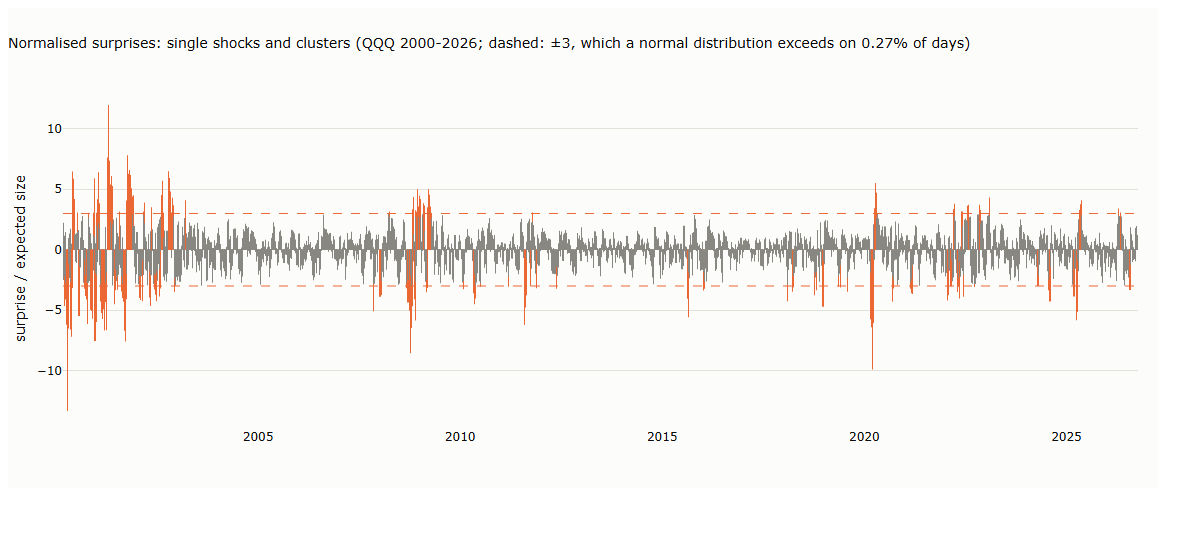

In [9]:
# C.4 normalised surprises, full history
zz = pd.Series(z_b, dates).iloc[250:]
fig = go.Figure()
fig.add_bar(x=zz.index, y=zz, name="Normalised surprise e/sqrt(S)", marker=dict(color=np.where(zz.abs() > 3, SERIES[1], MUTED), line=dict(width=0)))
for lv in (-3, 3):
    fig.add_hline(y=lv, line=dict(width=1, color=SERIES[1], dash="dash"))
fig.update_layout(title="Normalised surprises: single shocks and clusters (QQQ 2000-2026; dashed: ±3, which a normal distribution exceeds on 0.27% of days)",
                  yaxis_title="surprise / expected size", height=480, width=1150, margin=dict(t=80, b=60), showlegend=False)
save_figure(fig, "b_c04_surprises", FIG)
big = zz.abs() > 3
by_year = big.groupby(zz.index.year).sum()
print(f"share of days beyond ±3: {100 * big.mean():.2f}% (normal: 0.27%); standard deviation of z: {zz.std():.2f}; 2014-2018: {zz['2014':'2018'].std():.2f}")
print("days beyond ±3 by year (top 6):", by_year.sort_values(ascending=False).head(6).to_dict())
fig

## 3. One hidden state, by hand

Lecture 2's toy series, filtered with the level-only design. With $q/R = 1/6$ the steady-state gain is
exactly $1/3$, the $\alpha$ of EMA(5). Started at its steady-state uncertainty, the filter reproduces
EMA(5) bar for bar: the level-only Kalman filter *is* an EMA, with $\alpha$ set by the ratio $q/R$.

For the local level model the steady-state forecast uncertainty $u$ solves $u^2 - q\,u - q\,R = 0$
and the gain is $u/(u+R)$; with $q/R = 1/6$ this gives $u = R/2$ and a gain of $1/3$.

In [10]:
toy = np.array([100, 100.3, 100.5, 100.8, 101.0, 101.3, 101.5, 108.5, 102.5, 102.8, 103.0, 103.3, 103.5, 103.8])
r_toy, q_toy = 1.0, 1.0 / 6.0
u_star = (q_toy + np.sqrt(q_toy ** 2 + 4 * q_toy * r_toy)) / 2
gain_star = u_star / (u_star + r_toy)
F1, H1 = design(1)
res = kalman(toy, F1, H1, np.array([q_toy]), r_toy, start_uncertainty=(1 - gain_star) * u_star)
ema5 = ema(toy, 1 / 3)
tab = pd.DataFrame({"price": toy, "forecast": res["forecast"], "surprise": res["surprise"],
                    "gain": res["gain"], "level": res["states"][:, 0], "EMA(5)": ema5}).round(3)
tab.index.name = "bar"
print(f"steady-state gain = {gain_star:.4f} (EMA(5) alpha = 1/3)")
display(tab)
assert np.allclose(res["states"][:, 0], ema5)
t7 = 7
print(f"bar 7 by hand: forecast {res['forecast'][t7]:.3f}, surprise {toy[t7]:.1f} - {res['forecast'][t7]:.3f} = {res['surprise'][t7]:.3f}, "
      f"level = {res['forecast'][t7]:.3f} + {res['gain'][t7]:.4f} x {res['surprise'][t7]:.3f} = {res['states'][t7, 0]:.3f}")

steady-state gain = 0.3333 (EMA(5) alpha = 1/3)


,price,forecast,surprise,gain,level,EMA(5)
bar,,,,,,
0,100.0,100.000,0.000,0.333,100.000,100.000
1,100.3,100.000,0.300,0.333,100.100,100.100
2,100.5,100.100,0.400,0.333,100.233,100.233
3,100.8,100.233,0.567,0.333,100.422,100.422
4,101.0,100.422,0.578,0.333,100.615,100.615
5,101.3,100.615,0.685,0.333,100.843,100.843
6,101.5,100.843,0.657,0.333,101.062,101.062
7,108.5,101.062,7.438,0.333,103.541,103.541
8,102.5,103.541,-1.041,0.333,103.194,103.194


bar 7 by hand: forecast 101.062, surprise 108.5 - 101.062 = 7.438, level = 101.062 + 0.3333 x 7.438 = 103.541


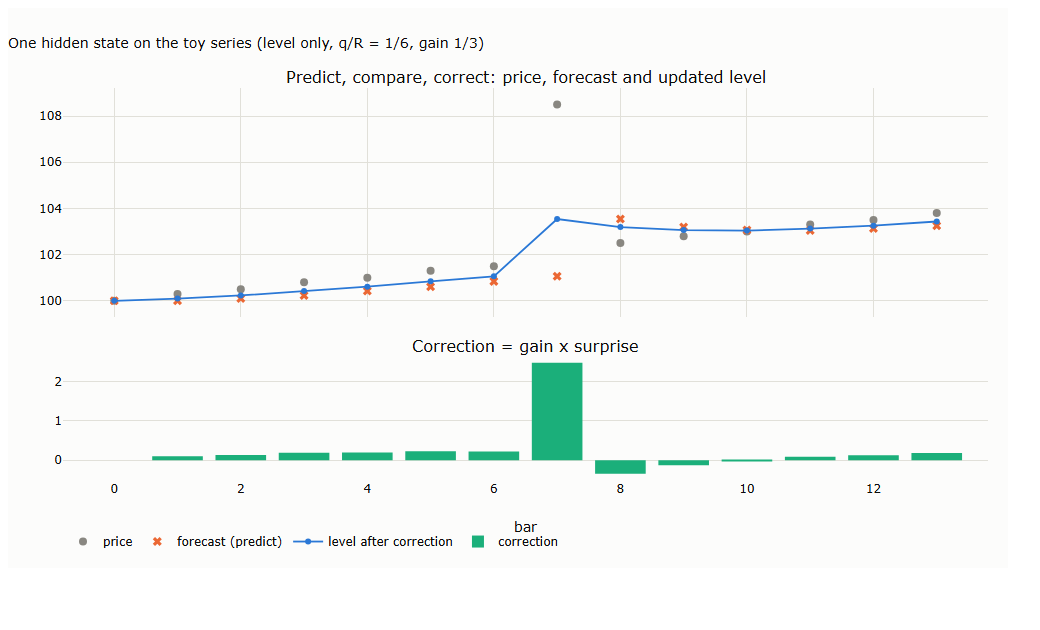

In [11]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1, row_heights=[0.65, 0.35],
                    subplot_titles=("Predict, compare, correct: price, forecast and updated level", "Correction = gain x surprise"))
bars = np.arange(len(toy))
fig.add_scatter(x=bars, y=toy, name="price", mode="markers", marker=dict(size=8, color=MUTED), row=1, col=1)
fig.add_scatter(x=bars, y=res["forecast"], name="forecast (predict)", mode="markers", marker=dict(size=8, symbol="x", color=SERIES[1]), row=1, col=1)
fig.add_scatter(x=bars, y=res["states"][:, 0], name="level after correction", mode="lines+markers", line=dict(width=1.8, color=SERIES[0]), row=1, col=1)
fig.add_bar(x=bars, y=res["gain"] * res["surprise"], name="correction", marker_color=SERIES[2], row=2, col=1)
fig.update_layout(title="One hidden state on the toy series (level only, q/R = 1/6, gain 1/3)", height=560, width=1000,
                  margin=dict(t=80, b=60), legend=dict(orientation="h", y=-0.12, x=0))
fig.update_xaxes(title_text="bar", row=2, col=1)
save_figure(fig, "c01_predict_compare_correct", FIG)
fig

**Only the ratio $q/R$ matters.** The same ten prices, filtered with $(q, R) = (1, 4)$ and
$(10, 40)$, with the starting uncertainty scaled by the same factor: the levels and gains are
identical; only the uncertainty band rescales, by $\sqrt{10}$. (Without scaling the start the agreement
is approximate during warm-up and exact once the start has been forgotten.)

,price,"level (q=1, R=4)","level (q=10, R=40)",gain A,gain B,band A (+-1 sd),band B (+-1 sd)
0,100.0,100.000,100.000,1.000,1.000,2.000,6.325
1,101.0,100.556,100.556,0.556,0.556,1.491,4.714
2,99.0,99.862,99.862,0.446,0.446,1.336,4.224
3,102.0,100.739,100.739,0.410,0.410,1.281,4.052
4,104.0,102.036,102.036,0.398,0.398,1.261,3.989
5,103.0,102.415,102.415,0.393,0.393,1.254,3.965
6,107.0,104.210,104.210,0.391,0.391,1.251,3.957
7,106.0,104.909,104.909,0.391,0.391,1.250,3.954
8,108.0,106.116,106.116,0.391,0.391,1.250,3.952
9,110.0,107.633,107.633,0.390,0.390,1.250,3.952


band ratio B/A at the last bar: 3.162 (sqrt(10) = 3.162)


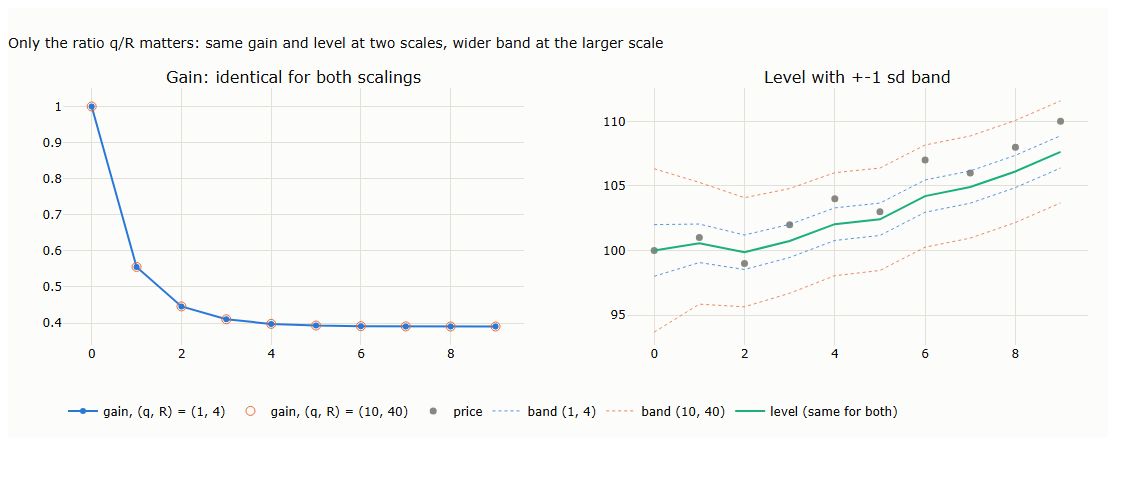

In [12]:
prices10 = np.array([100, 101, 99, 102, 104, 103, 107, 106, 108, 110.0])
A = kalman(prices10, F1, H1, np.array([1.0]), 4.0, start_uncertainty=1e6)
B = kalman(prices10, F1, H1, np.array([10.0]), 40.0, start_uncertainty=1e7)   # every variance scaled by 10, including the start
ratio_tab = pd.DataFrame({"price": prices10, "level (q=1, R=4)": A["states"][:, 0], "level (q=10, R=40)": B["states"][:, 0],
                          "gain A": A["gain"], "gain B": B["gain"], "band A (+-1 sd)": A["sd"][:, 0], "band B (+-1 sd)": B["sd"][:, 0]}).round(3)
display(ratio_tab)
assert np.allclose(A["states"], B["states"]) and np.allclose(A["gain"], B["gain"])
print(f"band ratio B/A at the last bar: {B['sd'][-1, 0] / A['sd'][-1, 0]:.3f} (sqrt(10) = {np.sqrt(10):.3f})")

fig = make_subplots(rows=1, cols=2, subplot_titles=("Gain: identical for both scalings", "Level with +-1 sd band"))
fig.add_scatter(x=np.arange(10), y=A["gain"], name="gain, (q, R) = (1, 4)", mode="lines+markers", line=dict(color=SERIES[0], width=2), row=1, col=1)
fig.add_scatter(x=np.arange(10), y=B["gain"], name="gain, (q, R) = (10, 40)", mode="markers", marker=dict(color=SERIES[1], size=9, symbol="circle-open"), row=1, col=2 - 1)
fig.add_scatter(x=np.arange(10), y=prices10, name="price", mode="markers", marker=dict(color=MUTED, size=7), row=1, col=2)
for j, (lab, R_) in enumerate((("(1, 4)", A), ("(10, 40)", B))):
    lvl, sd = R_["states"][:, 0], R_["sd"][:, 0]
    fig.add_scatter(x=np.arange(10), y=lvl + sd, mode="lines", line=dict(width=0.8, color=SERIES[j], dash="dot"), showlegend=False, row=1, col=2)
    fig.add_scatter(x=np.arange(10), y=lvl - sd, mode="lines", line=dict(width=0.8, color=SERIES[j], dash="dot"), name=f"band {lab}", row=1, col=2)
fig.add_scatter(x=np.arange(10), y=A["states"][:, 0], name="level (same for both)", mode="lines", line=dict(color=SERIES[2], width=2), row=1, col=2)
fig.update_layout(title="Only the ratio q/R matters: same gain and level at two scales, wider band at the larger scale",
                  height=430, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c02_ratio_invariance", FIG)
fig

## 4. Weights on past prices and matching memory

In steady state every design is a fixed linear smoother, so its weights on past prices can be read off
its response to a single unit price. Each design is matched to EMA(20) on the variance reduction factor
$\sum_k w_k^2 = 1/20$ (Lecture 2, section 6), by solving for its price noise $R$. The level-only design
then reproduces EMA(20) exactly; the slope designs put negative weights on old prices.

In [13]:
def level_weights(k, r_price, n=400, warm=3000, **kw):
    z = np.zeros(warm + n)
    base = run(z, k, r_price, **kw)["states"][:, 0]
    z[warm] = 1.0
    return (run(z, k, r_price, **kw)["states"][:, 0] - base)[warm:]


def match_r(k, target_vrf=1 / 20, **kw):
    lo, hi = 1e-7, 1e4
    for _ in range(70):
        mid = np.sqrt(lo * hi)
        w = level_weights(k, mid, **kw)
        lo, hi = (mid, hi) if (w ** 2).sum() / w.sum() ** 2 > target_vrf else (lo, mid)
    return mid


R_MATCH = {k: match_r(k) for k in (1, 2, 3)}
alpha20 = 2 / 21
rows = {}
for k in (1, 2, 3):
    w = level_weights(k, R_MATCH[k])
    ages = np.arange(len(w))
    rows[NAMES[k]] = {"price noise R (matched)": R_MATCH[k], "average age (bars)": (ages * w).sum() / w.sum(),
                      "variance reduction": (w ** 2).sum() / w.sum() ** 2, "smallest weight": w.min()}
w_ema = alpha20 * (1 - alpha20) ** np.arange(400)
rows["EMA(20)"] = {"price noise R (matched)": np.nan, "average age (bars)": (np.arange(400) * w_ema).sum() / w_ema.sum(),
                   "variance reduction": (w_ema ** 2).sum() / w_ema.sum() ** 2, "smallest weight": w_ema.min()}
display(pd.DataFrame(rows).T.round(4))
assert np.allclose(level_weights(1, R_MATCH[1])[:200], w_ema[:200], atol=1e-6)

,price noise R (matched),average age (bars),variance reduction,smallest weight
Level only,0.0100,9.5000,0.05,0.0000
Level + slope,0.2001,-0.0003,0.05,-0.0039
Level + slope + acceleration,12.4918,-0.8345,0.05,-0.0065
EMA(20),NaN,9.5000,0.05,0.0000


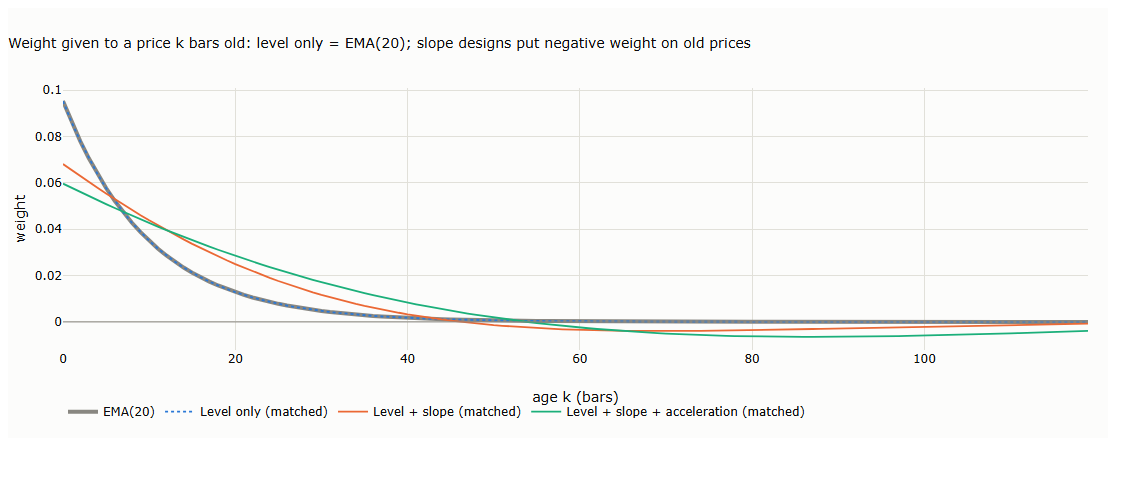

In [14]:
fig = go.Figure()
fig.add_scatter(x=np.arange(120), y=w_ema[:120], name="EMA(20)", mode="lines", line=dict(width=4, color=MUTED))
for j, k in enumerate((1, 2, 3)):
    fig.add_scatter(x=np.arange(120), y=level_weights(k, R_MATCH[k])[:120], name=f"{NAMES[k]} (matched)", mode="lines",
                    line=dict(width=1.8, color=SERIES[j], dash="dot" if k == 1 else "solid"))
fig.add_hline(y=0, line=dict(width=1, color=MUTED))
fig.update_layout(title="Weight given to a price k bars old: level only = EMA(20); slope designs put negative weight on old prices",
                  xaxis_title="age k (bars)", yaxis_title="weight", height=430, width=1100, margin=dict(t=80, b=70),
                  legend=dict(orientation="h", y=-0.18, x=0))
save_figure(fig, "c03_weights", FIG)
fig

## 5. Two forms of $Q$ for the level + slope design

*Diagonal*: the level and the slope may each change at random, independently (the level can jump by
itself, as prices gap). *Derived*: only the slope receives random kicks, and the level moves because
the slope moved during the bar, which over one bar gives $Q = q\begin{pmatrix}1/3 & 1/2\\ 1/2 & 1\end{pmatrix}$
(correlation 0.87 between the two changes). Both are matched to EMA(20) on variance reduction, then
shown on a price that jumps once.

diagonal Q: bars to cover half the jump 8, overshoot 18.9% of the jump
derived Q : bars to cover half the jump 8, overshoot 20.1% of the jump


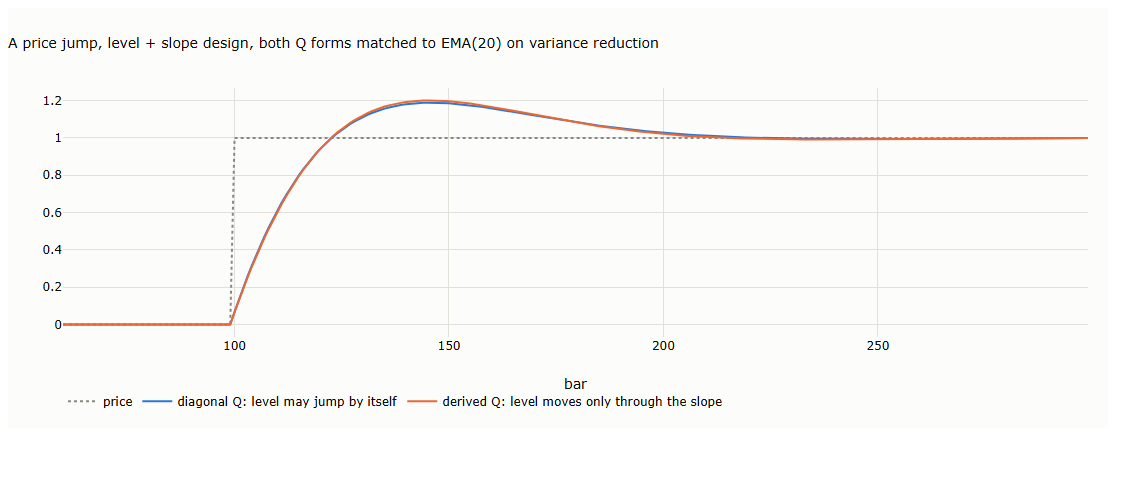

In [15]:
F2, H2 = design(2)
Q_derived = np.array([[1 / 3, 1 / 2], [1 / 2, 1.0]]) * 1e-4


def weights_q(full_q, r_price, n=400, warm=3000):
    z = np.zeros(warm + n)
    base = kalman(z, F2, H2, None, r_price, full_q=full_q)["states"][:, 0]
    z[warm] = 1.0
    return (kalman(z, F2, H2, None, r_price, full_q=full_q)["states"][:, 0] - base)[warm:]


lo, hi = 1e-7, 1e4
for _ in range(70):
    mid = np.sqrt(lo * hi)
    w = weights_q(Q_derived, mid)
    lo, hi = (mid, hi) if (w ** 2).sum() / w.sum() ** 2 > 1 / 20 else (lo, mid)
R_DERIVED = mid
step = np.r_[np.zeros(100), np.ones(200)]
lev_diag = run(step, 2, R_MATCH[2], start_uncertainty=1e3)["states"][:, 0]
lev_der = kalman(step, F2, H2, None, R_DERIVED, start_uncertainty=1e3, full_q=Q_derived)["states"][:, 0]
for lab, lv in (("diagonal Q", lev_diag), ("derived Q", lev_der)):
    print(f"{lab:10s}: bars to cover half the jump {int(np.argmax(lv[100:] >= 0.5))}, overshoot {100 * (lv.max() - 1):.1f}% of the jump")
fig = go.Figure()
fig.add_scatter(x=np.arange(60, 300), y=step[60:], name="price", mode="lines", line=dict(color=MUTED, dash="dot"))
fig.add_scatter(x=np.arange(60, 300), y=lev_diag[60:], name="diagonal Q: level may jump by itself", mode="lines", line=dict(color=SERIES[0], width=2))
fig.add_scatter(x=np.arange(60, 300), y=lev_der[60:], name="derived Q: level moves only through the slope", mode="lines", line=dict(color=SERIES[1], width=2))
fig.update_layout(title="A price jump, level + slope design, both Q forms matched to EMA(20) on variance reduction",
                  xaxis_title="bar", height=420, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c04_q_forms_jump", FIG)
fig

## 6. Design versus tuning

Which states a design has decides, for every setting, which kind of motion it follows with no lasting
gap and whether it overshoots a jump. Tuning only sets the speed. Each design at a slow and a very fast
setting, on a jump, a steady trend and a parabolic move (price noise $R = 1$):

In [16]:
tt = np.arange(3000.0)
tests = {"jump of 1": np.where(tt < 100, 0.0, 1.0), "steady trend (+0.01 per bar)": 0.01 * tt,
         "parabolic (1e-5 t^2)": 1e-5 * tt ** 2}
speeds = {"slow": np.array([1e-4, 1e-6, 1e-8]), "fast": np.array([1e-2, 1e-3, 1e-4])}
rows = []
for k in (1, 2, 3):
    F, Hh = design(k)
    row = {"design": NAMES[k]}
    for sp, q in speeds.items():
        lv = {name: kalman(y, F, Hh, q[:k], 1.0, start_uncertainty=1e3)["states"][:, 0] for name, y in tests.items()}
        row[f"jump overshoot, {sp} (%)"] = round(max(0.0, lv["jump of 1"][100:].max() - 1) * 100, 1)
        for name in ("steady trend (+0.01 per bar)", "parabolic (1e-5 t^2)"):
            y = tests[name]
            row[f"{name.split(' (')[0]} gap at bar 1500 / 2999, {sp}"] = f"{y[1500] - lv[name][1500]:.4f} / {y[2999] - lv[name][2999]:.4f}"
    rows.append(row)
design_tab = pd.DataFrame(rows).set_index("design")
display(design_tab.T)

design,Level only,Level + slope,Level + slope + acceleration
"jump overshoot, slow (%)",0.0,19.7,28.8
"steady trend gap at bar 1500 / 2999, slow",0.9950 / 0.9950,0.0000 / -0.0000,0.0000 / 0.0000
"parabolic gap at bar 1500 / 2999, slow",2.7860 / 5.7691,0.0195 / 0.0195,-0.0000 / 0.0000
"jump overshoot, fast (%)",0.0,16.6,23.0
"steady trend gap at bar 1500 / 2999, fast",0.0951 / 0.0951,-0.0000 / 0.0000,0.0000 / 0.0000
"parabolic gap at bar 1500 / 2999, fast",0.2835 / 0.5687,0.0006 / 0.0006,0.0000 / -0.0000


**How each design follows price after a jump.** Days on which each state points against the move,
after a jump followed by a flat price, and after a jump inside a continuing uptrend:

In [17]:
cases = {"jump, then flat": np.r_[np.zeros(100), np.ones(300)],
         "jump inside a continuing uptrend": 0.005 * np.arange(400.0) + np.where(np.arange(400.0) >= 100, 1.0, 0.0)}
rows = []
for case, y in cases.items():
    for sp, q in speeds.items():
        for k in (1, 2, 3):
            F, Hh = design(k)
            X = kalman(y, F, Hh, q[:k], 1.0, start_uncertainty=1e3)["states"][100:]

            def summary(mask):
                w = np.where(mask)[0]
                return f"{len(w)} (first +{w[0]})" if len(w) else "never"

            rows.append({"case": case, "speed": sp, "design": NAMES[k], "position": summary(y[100:] - X[:, 0] < 0),
                         "slope": summary(X[:, 1] < 0) if k >= 2 else "-", "acceleration": summary(X[:, 2] < 0) if k == 3 else "-"})
display(pd.DataFrame(rows).set_index(["case", "speed", "design"]))

position  \
case                             speed design                                          
jump, then flat                  slow  Level only                              never   
                                       Level + slope                 144 (first +34)   
                                       Level + slope + acceleration  136 (first +15)   
                                 fast  Level only                              never   
                                       Level + slope                  137 (first +6)   
                                       Level + slope + acceleration   153 (first +3)   
jump inside a continuing uptrend slow  Level only                              never   
                                       Level + slope                 144 (first +34)   
                                       Level + slope + acceleration  136 (first +15)   
                                 fast  Level only                              never   
                                       Level + slope                  148 (first +6)   
                                       Level + slope + acceleration   149 (first +3)   

                                                                                slope  \
case                             speed design                                           
jump, then flat                  slow  Level only                                   -   
                                       Level + slope                 144 (first +143)   
                                       Level + slope + acceleration   161 (first +61)   
                                 fast  Level only                                   -   
                                       Level + slope                  134 (first +27)   
                                       Level + slope + acceleration   146 (first +13)   
jump inside a continuing uptrend slow  Level only                                   -   
                                       Level + slope                            never   
                                       Level + slope + acceleration    48 (first +68)   
                                 fast  Level only                                   -   
                                       Level + slope                            never   
                                       Level + slope + acceleration    16 (first +13)   

                                                                        acceleration  
case                             speed design                                         
jump, then flat                  slow  Level only                                  -  
                                       Level + slope                               -  
                                       Level + slope + acceleration  168 (first +43)  
                                 fast  Level only                                  -  
                                       Level + slope                               -  
                                       Level + slope + acceleration   152 (first +9)  
jump inside a continuing uptrend slow  Level only                                  -  
                                       Level + slope                               -  
                                       Level + slope + acceleration  168 (first +43)  
                                 fast  Level only                                  -  
                                       Level + slope                               -  
                                       Level + slope + acceleration   148 (first +9)

## 7. Three designs on QQQ: states and readings

The three designs, each matched to EMA(20) on variance reduction, so that differences come from
structure rather than from smoothing more or less. Each state gives a reading: price above or below
the level (*position*), the sign of the slope, the sign of the acceleration.

Share of days each pair of readings agrees (QQQ):


,"Position, level only","Position, level + slope","Position, three-state","Slope, level + slope","Slope, three-state",Acceleration
"Position, level only",1.00,0.83,0.78,0.68,0.63,0.58
"Position, level + slope",0.83,1.00,0.91,0.53,0.48,0.52
"Position, three-state",0.78,0.91,1.00,0.52,0.45,0.51
"Slope, level + slope",0.68,0.53,0.52,1.00,0.89,0.70
"Slope, three-state",0.63,0.48,0.45,0.89,1.00,0.74
Acceleration,0.58,0.52,0.51,0.70,0.74,1.00


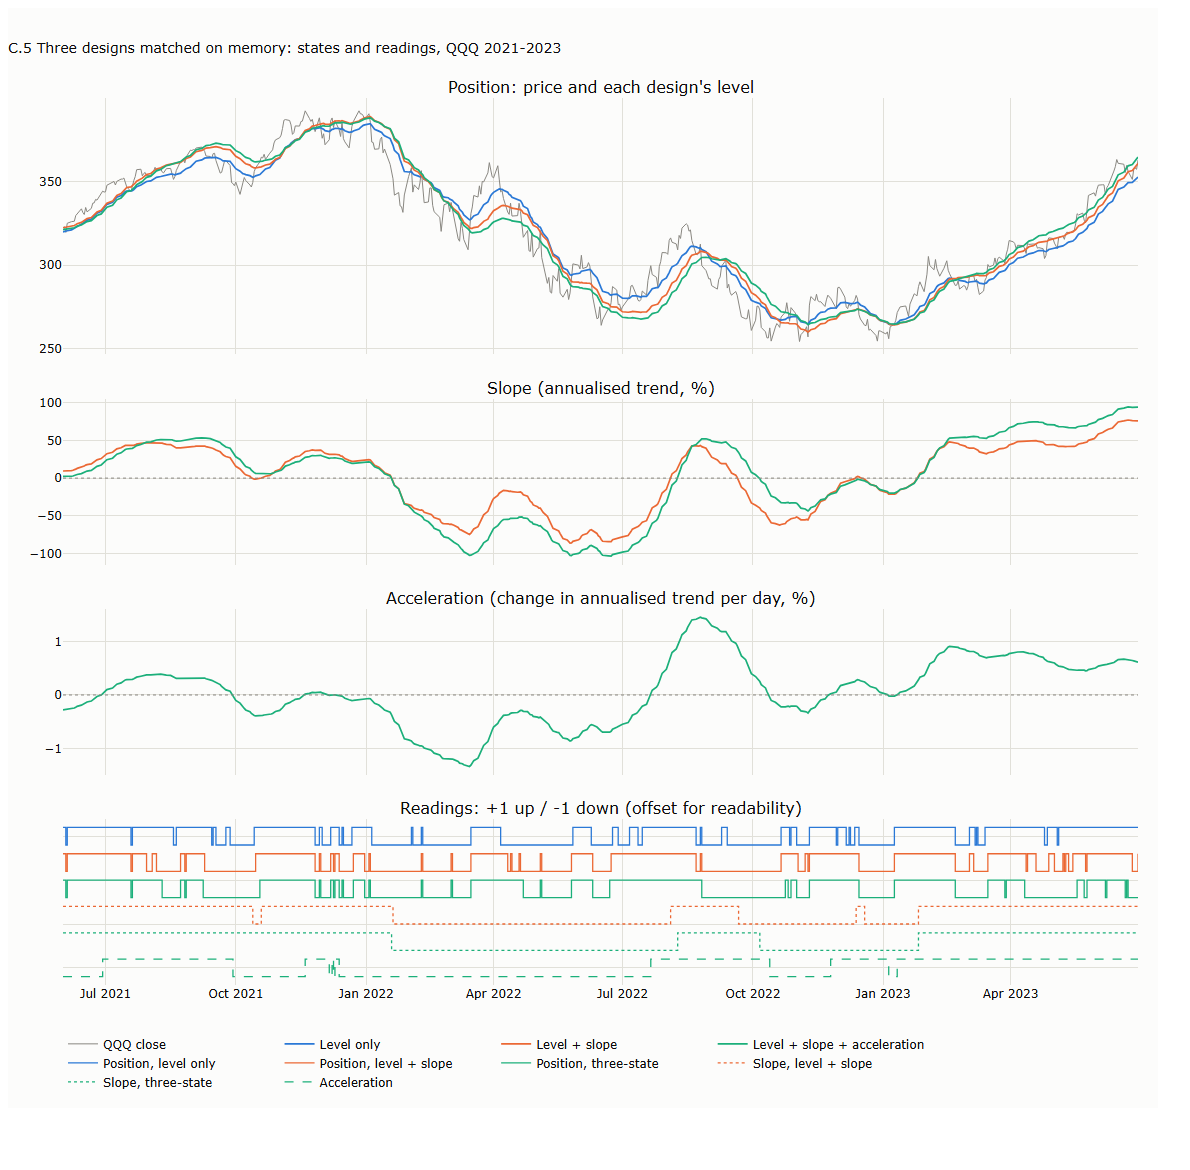

In [18]:
X = {k: run(y_qqq, k, R_MATCH[k])["states"] for k in (1, 2, 3)}
readings = pd.DataFrame({
    "Position, level only": np.sign(y_qqq - X[1][:, 0]), "Position, level + slope": np.sign(y_qqq - X[2][:, 0]),
    "Position, three-state": np.sign(y_qqq - X[3][:, 0]), "Slope, level + slope": np.sign(X[2][:, 1]),
    "Slope, three-state": np.sign(X[3][:, 1]), "Acceleration": np.sign(X[3][:, 2])}, index=dates)
R_ = readings.iloc[300:]
agree = (R_.T.dot(R_) / len(R_) * 0.5 + 0.5).round(2)
print("Share of days each pair of readings agrees (QQQ):")
display(agree)


def states_figure(lo, hi, title, name, shade=None):
    m = (dates >= lo) & (dates <= hi)
    fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05, row_heights=[0.34, 0.22, 0.22, 0.22],
                        subplot_titles=("Position: price and each design's level", "Slope (annualised trend, %)",
                                        "Acceleration (change in annualised trend per day, %)", "Readings: +1 up / -1 down (offset for readability)"))
    fig.add_scatter(x=dates[m], y=qqq.to_numpy()[m], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
    for j, k in enumerate((1, 2, 3)):
        fig.add_scatter(x=dates[m], y=np.exp(X[k][m, 0]), name=NAMES[k], mode="lines", line=dict(width=1.7, color=SERIES[j]), row=1, col=1)
    for j, k in ((1, 2), (2, 3)):
        fig.add_scatter(x=dates[m], y=100 * 252 * X[k][m, 1], showlegend=False, mode="lines", line=dict(width=1.7, color=SERIES[j]), row=2, col=1)
    fig.add_scatter(x=dates[m], y=100 * 252 * X[3][m, 2], showlegend=False, mode="lines", line=dict(width=1.7, color=SERIES[2]), row=3, col=1)
    cols = [SERIES[0], SERIES[1], SERIES[2], SERIES[1], SERIES[2], SERIES[2]]
    dash = ["solid", "solid", "solid", "dot", "dot", "dash"]
    for j, col in enumerate(readings):
        fig.add_scatter(x=dates[m], y=readings[col].to_numpy()[m] * 0.4 + (5 - j) * 1.2, name=col, mode="lines",
                        line=dict(width=1.3, color=cols[j], dash=dash[j], shape="hv"), row=4, col=1)
    for a, b in (shade or []):
        fig.add_vrect(x0=a, x1=b, fillcolor="rgba(120,120,120,0.10)", line_width=0)
    fig.update_yaxes(showticklabels=False, row=4, col=1)
    for r_ in (2, 3):
        fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=r_, col=1)
    fig.update_layout(title=title, height=1100, width=1150, margin=dict(t=90, b=80), legend=dict(orientation="h", y=-0.05, x=0))
    save_figure(fig, name, FIG)
    return fig


states_figure("2021-06-01", "2023-06-30", "C.5 Three designs matched on memory: states and readings, QQQ 2021-2023", "c05_three_designs")

## 8. The dials: shifting emphasis between states

The three-state design with four noise settings, each raising one entry of $Q$ a hundredfold from a
balanced case (price noise $R = 10^{-4}$). The settings are illustrative, not estimated.

,level roughness,level gap to price (RMS %),slope sign changes per year,days until slope < 0 after 2020-02-19 peak,days until slope > 0 after 2020-03-23 low
Balanced,0.33,2.24,8.01,6.0,15.0
Level emphasised,0.66,0.64,9.45,6.0,15.0
Slope emphasised,0.51,1.28,24.67,3.0,3.0
Acceleration emphasised,0.43,1.79,14.88,4.0,6.0


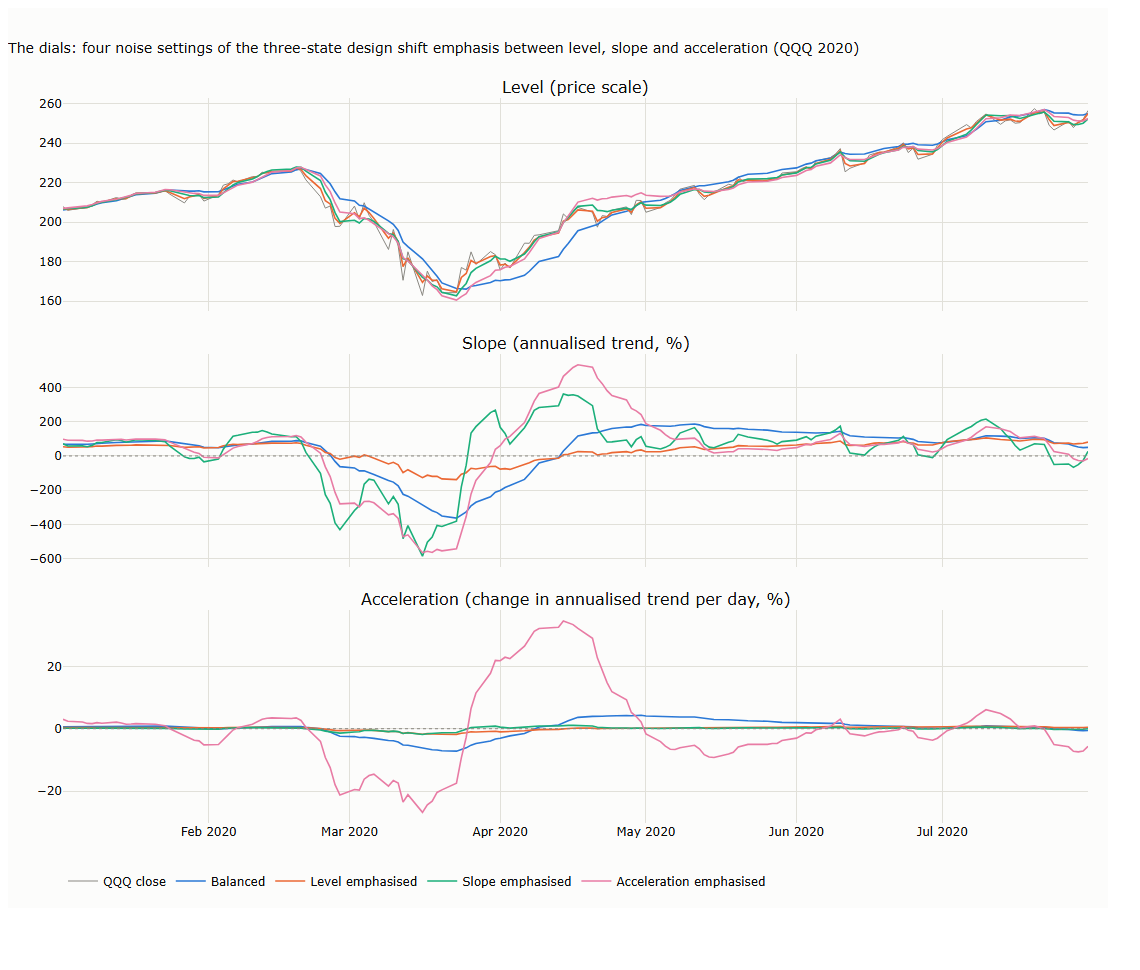

In [19]:
F3, H3 = design(3)
settings = {"Balanced": (1e-6, 1e-8, 1e-11), "Level emphasised": (1e-4, 1e-8, 1e-11),
            "Slope emphasised": (1e-6, 1e-6, 1e-11), "Acceleration emphasised": (1e-6, 1e-8, 1e-9)}
m = (dates >= "2020-01-01") & (dates <= "2020-07-31")
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                    subplot_titles=("Level (price scale)", "Slope (annualised trend, %)", "Acceleration (change in annualised trend per day, %)"))
fig.add_scatter(x=dates[m], y=qqq.to_numpy()[m], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
rows = {}
for j, (nm, q) in enumerate(settings.items()):
    Xs = kalman(y_qqq, F3, H3, np.array(q), 1e-4)["states"]
    for r_, (col, scale) in enumerate(((0, None), (1, 25200), (2, 25200)), start=1):
        yv = np.exp(Xs[m, 0]) if col == 0 else scale * Xs[m, col]
        fig.add_scatter(x=dates[m], y=yv, name=nm, showlegend=(r_ == 1), mode="lines", line=dict(width=1.6, color=SERIES[j]), row=r_, col=1)
    lvl, sl, yy = Xs[300:, 0], Xs[300:, 1], y_qqq[300:]
    s = pd.Series(Xs[:, 1], dates)

    def turn(d, sign):
        w = s.loc[d:]
        hit = w[np.sign(w) == sign]
        return dates.get_loc(hit.index[0]) - dates.get_loc(w.index[0])

    rows[nm] = {"level roughness": np.std(np.diff(lvl)) / np.std(np.diff(yy)), "level gap to price (RMS %)": 100 * np.sqrt(np.mean((lvl - yy) ** 2)),
                "slope sign changes per year": np.sum(np.diff(np.sign(sl)) != 0) / (len(sl) / 252),
                "days until slope < 0 after 2020-02-19 peak": turn("2020-02-19", -1), "days until slope > 0 after 2020-03-23 low": turn("2020-03-23", 1)}
for r_ in (2, 3):
    fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=r_, col=1)
fig.update_layout(title="The dials: four noise settings of the three-state design shift emphasis between level, slope and acceleration (QQQ 2020)",
                  height=900, width=1100, margin=dict(t=90, b=70), legend=dict(orientation="h", y=-0.06, x=0))
save_figure(fig, "c06_dials", FIG)
display(pd.DataFrame(rows).T.round(2))
fig

**What the overshoot means in price terms.** The slope is an annualised trend, so it is compared with
the fastest pace QQQ actually reached in the rebound (20-day log return, annualised), and with what
the slope would have implied over the following month had it persisted.

In [20]:
pace = pd.Series(y_qqq, dates).diff(20) * 252 / 20
w = slice("2020-03-23", "2020-06-30")
print(f"QQQ fastest 20-day pace after the March low: {100 * pace[w].max():.0f}% annualised ({pace[w].idxmax().date()})")
rows = {}
for nm, q in settings.items():
    Xs = pd.DataFrame(kalman(y_qqq, F3, H3, np.array(q), 1e-4)["states"], index=dates)
    sl, gap = Xs[1][w], np.exp(Xs[0] - y_qqq)[w] - 1
    t0 = sl.idxmax(); i0 = dates.get_loc(t0)
    rows[nm] = {"peak slope (% a year)": 100 * 252 * sl.max(), "date": t0.date(),
                "next 21 days implied by the slope (%)": 100 * (np.exp(21 * sl.max()) - 1),
                "next 21 days realised (%)": 100 * (qqq.iloc[i0 + 21] / qqq.iloc[i0] - 1),
                "largest level above price (%)": 100 * gap.max()}
display(pd.DataFrame(rows).T.round(1))

QQQ fastest 20-day pace after the March low: 285% annualised (2020-04-14)


,peak slope (% a year),date,next 21 days implied by the slope (%),next 21 days realised (%),largest level above price (%)
Balanced,186.211364,2020-05-11,16.786365,8.529101,4.106999
Level emphasised,87.158287,2020-06-10,7.533464,7.395432,1.875608
Slope emphasised,361.675492,2020-04-14,35.174485,3.530634,4.310706
Acceleration emphasised,531.632248,2020-04-17,55.741419,5.638904,6.953803


## 9. Starting the filter: warm-up

The level + slope design (matched) started 10% away from the true level, once with a confident start
(small starting uncertainty) and once with a *diffuse* start (large starting uncertainty), compared
with the same design started at the right level. EMA(20) started 10% off is shown for reference.

Kalman, confident start : starting error below 0.1% after 137 bars
Kalman, diffuse start   : starting error below 0.1% after 0 bars
EMA(20)                 : starting error below 0.1% after 70 bars


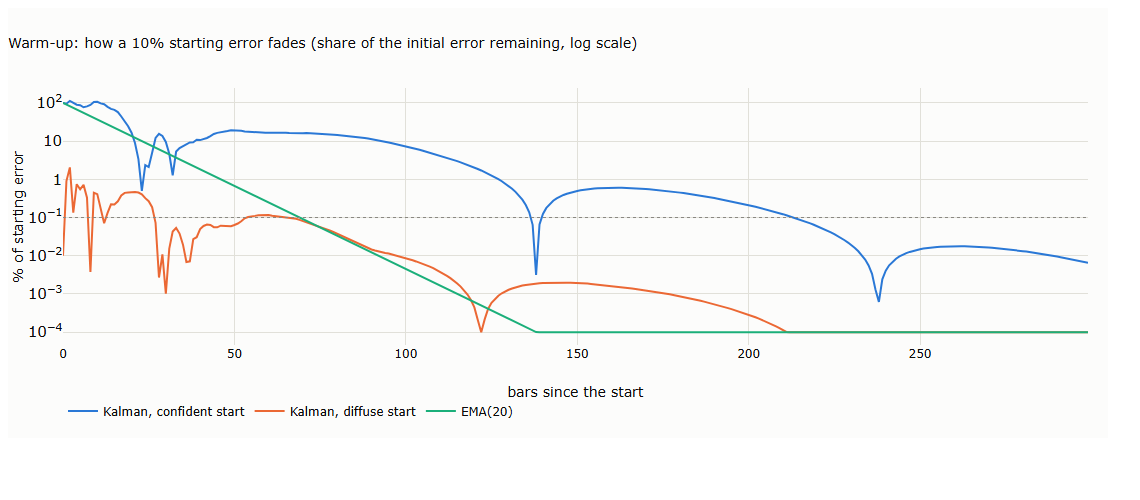

In [21]:
ref = run(y_qqq, 2, R_MATCH[2], start_uncertainty=1.0)["states"][:, 0]
off = np.log(1.1)
conf = run(y_qqq, 2, R_MATCH[2], start_uncertainty=1e-6, start_state=[y_qqq[0] + off, 0.0])["states"][:, 0]
diff_ = run(y_qqq, 2, R_MATCH[2], start_uncertainty=1e3, start_state=[y_qqq[0] + off, 0.0])["states"][:, 0]
e_ref = ema(y_qqq, alpha20)
e_off = ema(np.r_[y_qqq[0] + off, y_qqq[1:]], alpha20)
errs = {"Kalman, confident start": np.abs(conf - ref) / off, "Kalman, diffuse start": np.abs(diff_ - ref) / off,
        "EMA(20)": np.abs(e_off - e_ref) / off}
for nm, e in errs.items():
    below = np.where(e < 1e-3)[0]
    print(f"{nm:24s}: starting error below 0.1% after {below[0] if len(below) else 'never'} bars")
fig = go.Figure()
for j, (nm, e) in enumerate(errs.items()):
    fig.add_scatter(x=np.arange(300), y=100 * np.maximum(e[:300], 1e-6), name=nm, mode="lines", line=dict(width=2, color=SERIES[j]))
fig.add_hline(y=0.1, line=dict(width=1, color=MUTED, dash="dot"))
fig.update_layout(title="Warm-up: how a 10% starting error fades (share of the initial error remaining, log scale)",
                  xaxis_title="bars since the start", yaxis=dict(title="% of starting error", type="log", exponentformat="power"),
                  height=430, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c07_warmup", FIG)
fig

**Warm-up by design.** For each design matched to EMA(20): how many bars the gain needs to settle,
how far back its memory reaches (older prices carry under 0.1% of the total absolute weight), and how
quickly a 10% starting error in the level, and the starting slope, are forgotten with a diffuse and a
confident start, measured against the same design started at the right level.

In [22]:
rows = {}
for k in (1, 2, 3):
    g = run(np.zeros(3000), k, R_MATCH[k], start_uncertainty=1e3)["gain"]
    settle = int(np.argmax(np.abs(g - g[-1]) < 0.01 * g[-1]))
    w = level_weights(k, R_MATCH[k], n=2000)
    tail = np.array([np.abs(w[j:]).sum() for j in range(len(w))]) / np.abs(w).sum()
    horizon = int(np.argmax(tail < 1e-3))
    ref_k = run(y_qqq, k, R_MATCH[k])["states"]
    s0 = np.zeros(k); s0[0] = y_qqq[0] + off
    row = {"gain settled within 1% (bars)": settle, "memory horizon (bars)": horizon}
    for nm, p0 in (("diffuse", 1e3), ("confident", 1e-6)):
        Xw = run(y_qqq, k, R_MATCH[k], start_uncertainty=p0, start_state=s0)["states"]
        e_lvl = np.abs(Xw[:, 0] - ref_k[:, 0]) / off
        b = np.where(e_lvl < 1e-3)[0]
        row[f"level error < 0.1%, {nm} start (bars)"] = int(b[0]) if len(b) else None
        if k >= 2:
            e_sl = 25200 * np.abs(Xw[:, 1] - ref_k[:, 1])
            later = np.where(e_sl >= 1.0)[0]
            row[f"slope within 1%/yr for good, {nm} start (bars)"] = int(later[-1] + 1) if len(later) else 0
    rows[NAMES[k]] = row
warm_tab = pd.DataFrame(rows).T
display(warm_tab)

,gain settled within 1% (bars),memory horizon (bars),"level error < 0.1%, diffuse start (bars)","level error < 0.1%, confident start (bars)","slope within 1%/yr for good, diffuse start (bars)","slope within 1%/yr for good, confident start (bars)"
Level only,26.0,70.0,0.0,73.0,NaN,NaN
Level + slope,86.0,197.0,0.0,137.0,24.0,163.0
Level + slope + acceleration,184.0,436.0,23.0,145.0,174.0,346.0


**Long memories: how much burn-in?** Structural trends call for a memory of a year or more. Here the
long memory is placed on the slope, as in Holt's method: for the level + slope design, $q_{slope}$ is chosen
so that the slope's weights on past prices reach back as far as those of EMA(N) (to 0.1% of the total
absolute weight), with a faster level ($q_{level} = 0.1\,R$). Each design is started with a diffuse start at
22 dates (every 500 bars from bar 1,500, leaving at least 2,600 bars) across SPY, QQQ, GLD and AGG, run for
a burn-in of N or 2N bars, and compared over the following year with the same design run on the full history.

In [23]:
F2, H2 = design(2)


def ls_steady_weights(q_level, q_slope, n, r_price=1.0):
    Q = np.diag([q_level, q_slope]); P = np.eye(2)
    for _ in range(400000):
        Pp = F2 @ P @ F2.T + Q; K = Pp @ H2 / (H2 @ Pp @ H2 + r_price); Pn = Pp - np.outer(K, H2 @ Pp)
        if np.allclose(Pn, P, rtol=1e-13, atol=0): break
        P = Pn
    A = (np.eye(2) - np.outer(K, H2)) @ F2
    W, v = np.empty((n, 2)), K.copy()
    for j in range(n):
        W[j] = v; v = A @ v
    return W


def horizon(w):
    tail = np.cumsum(np.abs(w)[::-1])[::-1] / np.abs(w).sum()
    return int(np.argmax(tail < 1e-3))


def ls_filter(y, q_level, q_slope, p0=1e3):
    Q = np.diag([q_level, q_slope]); x = np.array([y[0], 0.0]); P = np.eye(2) * p0; X = np.empty((len(y), 2))
    for t, p in enumerate(y):
        x = F2 @ x; P = F2 @ P @ F2.T + Q; K = P @ H2 / (H2 @ P @ H2 + 1.0)
        x = x + K * (p - H2 @ x); P = P - np.outer(K, H2 @ P); X[t] = x
    return X


logs = {t: np.log(C[t].dropna().to_numpy()) for t in TICKERS}
rows = {}
Q_LEVEL = 0.1
for N in (252, 500):
    target = int(np.ceil(np.log(1e-3) / np.log(1 - 2 / (N + 1))))       # memory horizon of EMA(N)
    lo, hi = 1e-14, 1e-1
    for _ in range(80):
        mid = np.sqrt(lo * hi)
        lo, hi = (lo, mid) if horizon(ls_steady_weights(Q_LEVEL, mid, 20 * N)[:, 1]) < target else (mid, hi)
    q_slope = mid
    W = ls_steady_weights(Q_LEVEL, q_slope, 20 * N)
    for burn in (N, 2 * N):
        sa, sd, pa = [], [], []
        for t in TICKERS:
            y = logs[t]; ref = ls_filter(y, Q_LEVEL, q_slope)
            for s0 in range(1500, len(y) - 2600, 500):
                seg = slice(s0, s0 + burn + 252)
                Xd = ls_filter(y[seg], Q_LEVEL, q_slope); R_ = ref[seg]; ys = y[seg]
                sa.append(np.mean(np.sign(Xd[burn:, 1]) == np.sign(R_[burn:, 1])))
                sd.append(25200 * np.abs(Xd[burn:, 1] - R_[burn:, 1]).mean())
                pa.append(np.mean(np.sign(ys[burn:] - Xd[burn:, 0]) == np.sign(ys[burn:] - R_[burn:, 0])))
        rows[(f"trend horizon {N}", f"burn-in {burn}")] = {
            "slope memory horizon (bars)": horizon(W[:, 1]), "EMA(N) memory horizon (bars)": target,
            "slope sign agrees (%)": 100 * np.median(sa), "slope gap (% a year)": np.median(sd),
            "position agrees (%)": 100 * np.median(pa), "starts": len(sa)}
display(pd.DataFrame(rows).T.round(2))

slope memory horizon (bars)  \
trend horizon 252 burn-in 252                         871.0   
                  burn-in 504                         871.0   
trend horizon 500 burn-in 500                        1726.0   
                  burn-in 1000                       1726.0   

                                EMA(N) memory horizon (bars)  \
trend horizon 252 burn-in 252                          871.0   
                  burn-in 504                          871.0   
trend horizon 500 burn-in 500                         1727.0   
                  burn-in 1000                        1727.0   

                                slope sign agrees (%)  slope gap (% a year)  \
trend horizon 252 burn-in 252                    99.4                  1.03   
                  burn-in 504                   100.0                  0.16   
trend horizon 500 burn-in 500                   100.0                  1.31   
                  burn-in 1000                  100.0                  0.18   

                                position agrees (%)  starts  
trend horizon 252 burn-in 252                 99.21    22.0  
                  burn-in 504                100.00    22.0  
trend horizon 500 burn-in 500                 99.21    22.0  
                  burn-in 1000               100.00    22.0

For contrast, the level + slope design matched on the level's smoothing to EMA(252), with the fixed noise
ratios of section 4 ($q_{level} = 10^{-4}$, $q_{slope} = 10^{-6}$, price noise solved): the long memory then
spreads over the whole filter.

In [24]:
lo, hi = 1e-8, 1e7
for _ in range(80):
    mid = np.sqrt(lo * hi)
    w = ls_steady_weights(1e-4, 1e-6, 252 * 40, r_price=mid)[:, 0]
    lo, hi = (mid, hi) if (w ** 2).sum() / w.sum() ** 2 > 1 / 252 else (lo, mid)
w = ls_steady_weights(1e-4, 1e-6, 252 * 40, r_price=mid)[:, 0]
print(f"price noise matched: {mid:.4g}; level weight on prices older than one year: {100 * np.abs(w[252:]).sum() / np.abs(w).sum():.0f}%; "
      f"memory horizon {horizon(w)} bars")

price noise matched: 5070; level weight on prices older than one year: 36%; memory horizon 2529 bars


## 10. Extensions, profiled not ranked

Three changes to the level + slope design (matched), each describing a different belief about the data:

- **Robust update**: a surprise larger than 3 times the recent typical surprise (a running estimate
  over about a year, using past data only) is capped before correcting, a simple version of the idea in
  Masreliez and Martin (1977), motivated by fat-tailed surprises. The cap is relative to recent
  surprises rather than to the model's own surprise variance, because matching memory to EMA(20) sets
  the model's price noise far above the actual daily noise, and a cap on that scale would almost never bind.
- **Price noise from the bar's range**: $R$ changes every bar in proportion to the Parkinson variance
  of that bar (Lecture 3), scaled to the same average.
- **Damped slope**: the slope fades by a factor 0.98 per bar unless renewed by the data.

Normalised surprises of the level + slope design (standardised to unit variance):


,share |z| > 3 (%),normal would give (%),skewness,excess kurtosis
SPY,1.26,0.27,-0.64,5.87
QQQ,1.69,0.27,0.10,3.31
GLD,1.17,0.27,-0.23,2.07
AGG,1.77,0.27,-0.48,12.03


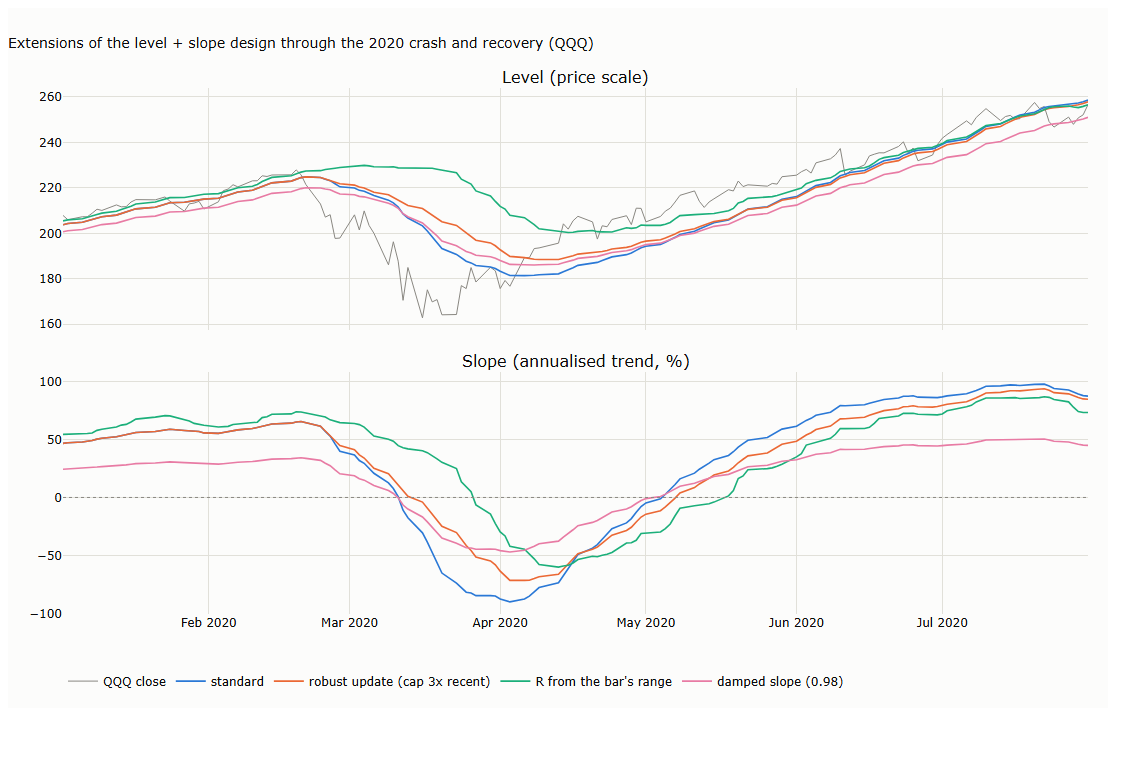

In [25]:
def parkinson(t):
    return (np.log(H[t] / L[t]) ** 2 / (4 * np.log(2))).reindex(C[t].dropna().index)


park_q = parkinson("QQQ").to_numpy()
park_q = np.maximum(park_q, np.nanquantile(park_q[park_q > 0], 0.01))
variants = {"standard": {}, "robust update (cap 3x recent)": {"cap": 3.0},
            "R from the bar's range": {"r_series": R_MATCH[2] * park_q / np.nanmean(park_q)},
            "damped slope (0.98)": {"damping": 0.98}}
VX = {nm: run(y_qqq, 2, R_MATCH[2], **kw) for nm, kw in variants.items()}
z_std = VX["standard"]["z"][300:]
tails = {}
for t in TICKERS:
    yt = np.log(C[t].dropna().to_numpy())
    zt = run(yt, 2, R_MATCH[2])["z"][300:]
    zt = zt / np.std(zt)
    tails[t] = {"share |z| > 3 (%)": 100 * np.mean(np.abs(zt) > 3), "normal would give (%)": 100 * 2 * norm.sf(3),
                "skewness": skew(zt), "excess kurtosis": kurtosis(zt)}
print("Normalised surprises of the level + slope design (standardised to unit variance):")
display(pd.DataFrame(tails).T.round(2))

m = (dates >= "2020-01-01") & (dates <= "2020-07-31")
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08, subplot_titles=("Level (price scale)", "Slope (annualised trend, %)"))
fig.add_scatter(x=dates[m], y=qqq.to_numpy()[m], name="QQQ close", mode="lines", line=dict(width=1, color=MUTED), row=1, col=1)
for j, (nm, out) in enumerate(VX.items()):
    fig.add_scatter(x=dates[m], y=np.exp(out["states"][m, 0]), name=nm, mode="lines", line=dict(width=1.6, color=SERIES[j]), row=1, col=1)
    fig.add_scatter(x=dates[m], y=25200 * out["states"][m, 1], showlegend=False, mode="lines", line=dict(width=1.6, color=SERIES[j]), row=2, col=1)
fig.add_hline(y=0, line=dict(width=1, color=MUTED, dash="dot"), row=2, col=1)
fig.update_layout(title="Extensions of the level + slope design through the 2020 crash and recovery (QQQ)",
                  height=700, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.1, x=0))
save_figure(fig, "c08_extensions_2020", FIG)
fig

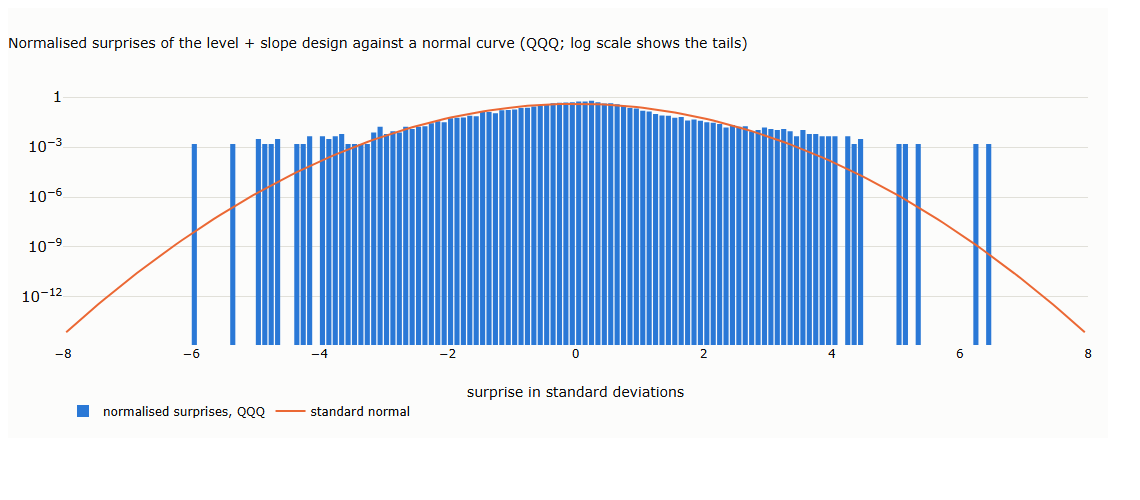

In [26]:
zs = z_std / np.std(z_std)
edges = np.linspace(-8, 8, 161)
counts, _ = np.histogram(zs, bins=edges)
centres = (edges[:-1] + edges[1:]) / 2
fig = go.Figure()
fig.add_bar(x=centres, y=counts / (len(zs) * np.diff(edges)), name="normalised surprises, QQQ", marker_color=SERIES[0])
fig.add_scatter(x=centres, y=norm.pdf(centres), name="standard normal", mode="lines", line=dict(width=2, color=SERIES[1]))
fig.update_layout(title="Normalised surprises of the level + slope design against a normal curve (QQQ; log scale shows the tails)",
                  yaxis=dict(type="log", exponentformat="power"), xaxis_title="surprise in standard deviations", height=430, width=1100,
                  margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c09_surprises", FIG)
fig

## 11. A nonlinear case: hidden volatility from daily ranges

The hidden state is the log daily variance $h_t$ (a random walk); the measurement is the bar's high-low
range in log terms, $\text{range}_t = \ln(H_t/L_t)$. For a driftless Brownian motion with variance
$e^{h_t}$ over the day, $\text{range}_t = e^{h_t/2}\,\rho$, where $\rho$ is the range of a standard
Brownian motion over unit time (mean $\sqrt{8/\pi}$, Lecture 3). Two ways to filter it:

- **Nonlinear measurement** $\text{range}_t = e^{h_t/2}\,\mathbb E[\rho] + \text{noise}$: the extended
  (EKF) and unscented (UKF) filters.
- **Transform first**: $\ln \text{range}_t = h_t/2 + \mathbb E[\ln\rho] + \varepsilon_t$ is linear in
  $h_t$, so the ordinary Kalman filter applies (the route of Alizadeh, Brandt and Diebold, 2002).

The moments of $\rho$ and $\ln\rho$ are computed here by simulation on a fine grid (our calculation).

In [27]:
rng = np.random.default_rng(13)
n_paths, n_steps = 20000, 2000
rho = np.empty(n_paths)
for i in range(0, n_paths, 2000):
    w = np.cumsum(rng.standard_normal((2000, n_steps)) / np.sqrt(n_steps), axis=1)
    w = np.concatenate([np.zeros((2000, 1)), w], axis=1)
    rho[i:i + 2000] = w.max(axis=1) - w.min(axis=1)
mean_rho, var_rho = rho.mean(), rho.var()
mean_lr, var_lr = np.log(rho).mean(), np.log(rho).var()
print(f"range of a standard Brownian motion (simulated): mean {mean_rho:.4f} (sqrt(8/pi) = {np.sqrt(8 / np.pi):.4f}), variance {var_rho:.4f}")
print(f"log range: mean {mean_lr:.4f}, variance {var_lr:.4f}, skewness {skew(np.log(rho)):.3f}, excess kurtosis {kurtosis(np.log(rho)):.3f}")

range of a standard Brownian motion (simulated): mean 1.5720 (sqrt(8/pi) = 1.5958), variance 0.2266
log range: mean 0.4093, variance 0.0850, skewness 0.158, excess kurtosis -0.252


q for the log-variance random walk, by maximum likelihood on the linear model: 0.1259


Agreement between the three estimates of annualised session volatility (SPY):


,correlation with the linear filter,mean absolute difference (vol points)
linear on log range,1.000,0.000
extended (EKF) on range,0.946,0.972
iterated EKF on range,0.970,1.281
unscented (UKF) on range,0.940,0.886


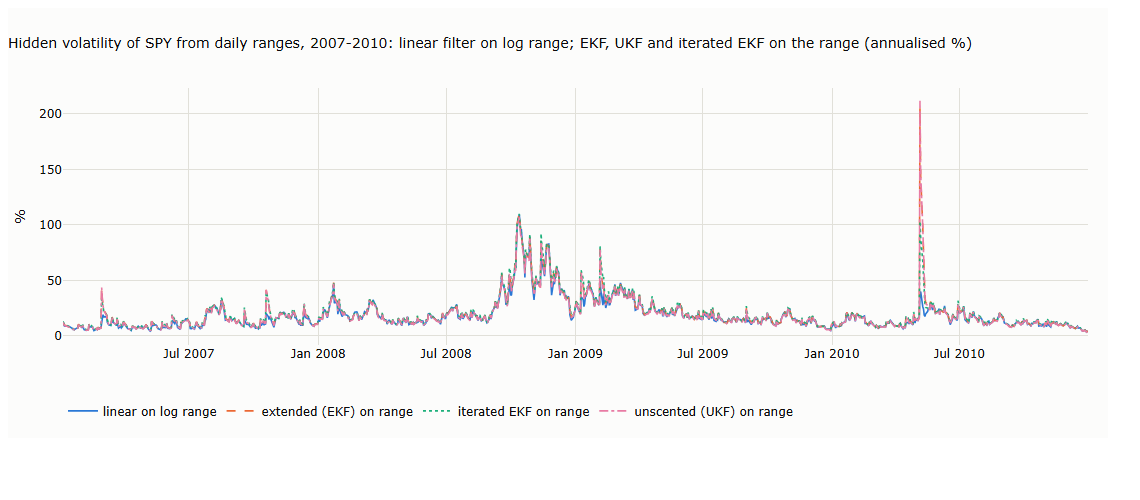

In [28]:
def vol_filters(rng_obs, q_h):
    T = len(rng_obs)
    out = {}
    # linear Kalman filter on log range
    h, P = np.log(np.nanmedian(rng_obs) ** 2 / mean_rho ** 2), 1.0
    lin, ll = np.empty(T), 0.0
    for t in range(T):
        P = P + q_h
        f = 0.5 * h + mean_lr
        S = 0.25 * P + var_lr
        e = np.log(rng_obs[t]) - f
        ll += -0.5 * (np.log(2 * np.pi * S) + e ** 2 / S)
        K = 0.5 * P / S
        h, P = h + K * e, (1 - 0.5 * K) * P
        lin[t] = h
    out["linear on log range"], out["loglik"] = lin, ll
    # extended Kalman filter on the range itself
    h, P = lin[0], 1.0
    ekf = np.empty(T)
    for t in range(T):
        P = P + q_h
        g = mean_rho * np.exp(h / 2)
        Hj = 0.5 * g
        Rm = np.exp(h) * var_rho
        S = Hj * P * Hj + Rm
        K = P * Hj / S
        h, P = h + K * (rng_obs[t] - g), (1 - K * Hj) * P
        ekf[t] = h
    out["extended (EKF) on range"] = ekf
    # iterated EKF: re-linearise at the updated estimate until it settles (Bell and Cathey, 1993)
    h, P = lin[0], 1.0
    iekf = np.empty(T)
    for t in range(T):
        P = P + q_h
        h_prior, h_lin = h, h
        Rm = np.exp(h_prior) * var_rho
        for _ in range(20):
            g = mean_rho * np.exp(h_lin / 2)
            Hj = 0.5 * g
            S = Hj * P * Hj + Rm
            K = P * Hj / S
            h_new = h_prior + K * (rng_obs[t] - g - Hj * (h_prior - h_lin))
            if abs(h_new - h_lin) < 1e-10:
                break
            h_lin = h_new
        h, P = h_new, (1 - K * Hj) * P
        iekf[t] = h
    out["iterated EKF on range"] = iekf
    # unscented Kalman filter on the range itself (scalar state, 3 sigma points)
    alpha, beta, kappa = 1e-1, 2.0, 0.0
    lam = alpha ** 2 * (1 + kappa) - 1
    wm = np.array([lam / (1 + lam), 0.5 / (1 + lam), 0.5 / (1 + lam)])
    wc = wm.copy(); wc[0] += 1 - alpha ** 2 + beta
    h, P = lin[0], 1.0
    ukf = np.empty(T)
    for t in range(T):
        P = P + q_h
        sp = np.array([h, h + np.sqrt((1 + lam) * P), h - np.sqrt((1 + lam) * P)])
        g = mean_rho * np.exp(sp / 2)
        g_mean = wm @ g
        Rm = np.exp(h) * var_rho
        S = wc @ (g - g_mean) ** 2 + Rm
        Pxy = wc @ ((sp - h) * (g - g_mean))
        K = Pxy / S
        h, P = h + K * (rng_obs[t] - g_mean), P - K * S * K
        ukf[t] = h
    out["unscented (UKF) on range"] = ukf
    return out


spy_rng = np.log(H["SPY"] / L["SPY"]).reindex(C["SPY"].dropna().index)
spy_rng = spy_rng.clip(lower=spy_rng[spy_rng > 0].quantile(0.001)).to_numpy()
grid = np.logspace(-4, -0.5, 36)
lls = [vol_filters(spy_rng, q)["loglik"] for q in grid]
q_best = grid[int(np.argmax(lls))]
print(f"q for the log-variance random walk, by maximum likelihood on the linear model: {q_best:.4g}")
VF = vol_filters(spy_rng, q_best)
vol = {k: 100 * np.sqrt(252 * np.exp(v)) for k, v in VF.items() if k != "loglik"}
vdf = pd.DataFrame(vol, index=C["SPY"].dropna().index).iloc[100:]
print("Agreement between the three estimates of annualised session volatility (SPY):")
display(pd.DataFrame({"correlation with the linear filter": vdf.corr().iloc[0],
                      "mean absolute difference (vol points)": (vdf.sub(vdf.iloc[:, 0], axis=0)).abs().mean()}).round(3))
m = (vdf.index >= "2007-01-01") & (vdf.index <= "2010-12-31")
fig = go.Figure()
for j, col in enumerate(vdf):
    fig.add_scatter(x=vdf.index[m], y=vdf[col][m], name=col, mode="lines", line=dict(width=1.6, color=SERIES[j], dash=["solid", "dash", "dot", "dashdot"][j]))
fig.update_layout(title="Hidden volatility of SPY from daily ranges, 2007-2010: linear filter on log range; EKF, UKF and iterated EKF on the range (annualised %)",
                  yaxis_title="%", height=430, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c11_volatility_filters", FIG)
fig

**The flash crash, 6 May 2010.** SPY's range that day was about 10.8%. The table compares each filter's
estimate before and after the update with that day's range, against the volatility the day's range alone
implies (Parkinson, Lecture 3).

In [29]:
day = pd.Timestamp("2010-05-06")
i_day = C["SPY"].dropna().index.get_loc(day)
r_day = spy_rng[i_day]
print(f"log range on 6 May 2010: {r_day:.4f}; Parkinson volatility of that day alone: {100 * np.sqrt(252 * r_day ** 2 / (4 * np.log(2))):.0f}% annualised")
vol_all = pd.DataFrame({k: 100 * np.sqrt(252 * np.exp(v)) for k, v in VF.items() if k != "loglik"}, index=C["SPY"].dropna().index)
display(vol_all.iloc[i_day - 1:i_day + 2].T.round(0))

log range on 6 May 2010: 0.1082; Parkinson volatility of that day alone: 103% annualised


Date,2010-05-05,2010-05-06,2010-05-07
linear on log range,16.0,39.0,40.0
extended (EKF) on range,16.0,206.0,145.0
iterated EKF on range,16.0,103.0,89.0
unscented (UKF) on range,15.0,212.0,146.0


**Linearisation versus sigma points.** The filter's belief about $h$ is normal, with mean $m$ and
variance $P$; the forecast of the range needs the mean and variance of $\mathbb E[
ho]\,e^{h/2}$ under
that belief. These are known exactly for a lognormal, so the EKF's tangent and the UKF's three sigma
points can be checked against them (our calculation). Values are relative to the curve at the estimate,
$\mathbb E[
ho]\,e^{m/2}$, at the filter's typical forecast uncertainty and at $P = 1$, as early in a warm-up.

forecast mean  forecast sd
typical (P = 0.28) exact                     1.0355       0.2784
                   EKF (tangent)             1.0000       0.2642
                   UKF, alpha = 0.01         1.0349       0.2688
                   UKF, alpha = 0.1          1.0349       0.2688
                   UKF, alpha = 1.0          1.0351       0.2719
uncertain (P = 1)  exact                     1.1331       0.6039
                   EKF (tangent)             1.0000       0.5000
                   UKF, alpha = 0.01         1.1250       0.5303
                   UKF, alpha = 0.1          1.1250       0.5305
                   UKF, alpha = 1.0          1.1276       0.5515

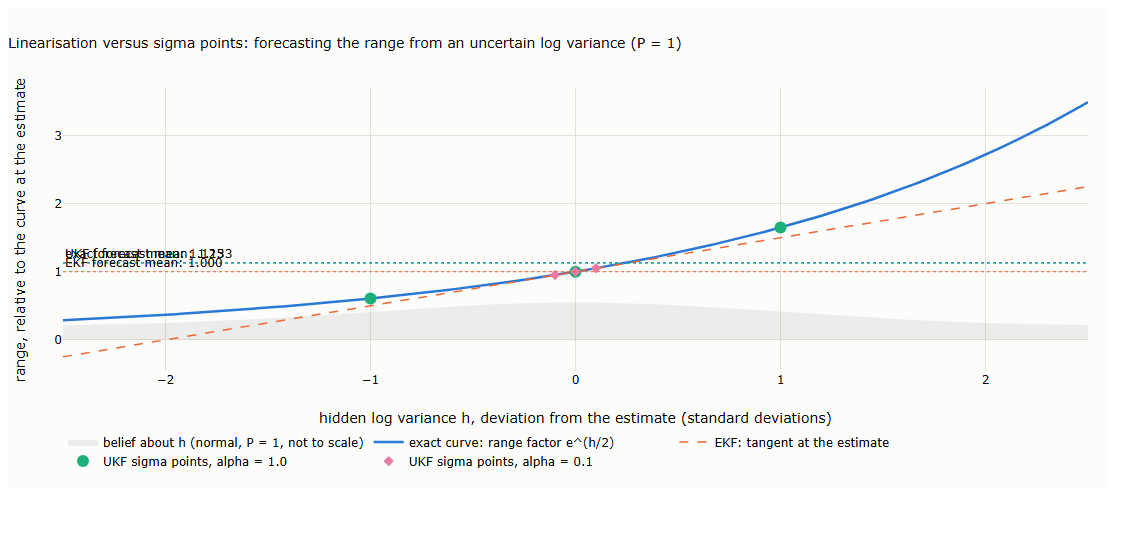

In [30]:
def unscented(mean, var, alpha, beta=2.0, kappa=0.0):
    lam = alpha ** 2 * (1 + kappa) - 1
    spread = np.sqrt((1 + lam) * var)
    points = np.array([mean, mean + spread, mean - spread])
    wm = np.array([lam, 0.5, 0.5]) / (1 + lam)
    wc = wm.copy(); wc[0] += 1 - alpha ** 2 + beta
    vals = np.exp(points / 2)
    m_ = wm @ vals
    return points, m_, np.sqrt(wc @ (vals - m_) ** 2)


P_ = 1.0
for _ in range(2000):                     # steady uncertainty of the linear filter on log range
    Pp = P_ + q_best
    K_ = 0.5 * Pp / (0.25 * Pp + var_lr)
    P_ = (1 - 0.5 * K_) * Pp
rows = {}
for label, var in ((f"typical (P = {Pp:.2f})", Pp), ("uncertain (P = 1)", 1.0)):
    rows[(label, "exact")] = {"forecast mean": np.exp(var / 8), "forecast sd": np.sqrt(np.exp(var / 4) * (np.exp(var / 4) - 1))}
    rows[(label, "EKF (tangent)")] = {"forecast mean": 1.0, "forecast sd": 0.5 * np.sqrt(var)}
    for a in (0.01, 0.1, 1.0):
        _, m_, sd_ = unscented(0.0, var, a)
        rows[(label, f"UKF, alpha = {a}")] = {"forecast mean": m_, "forecast sd": sd_}
display(pd.DataFrame(rows).T.round(4))

x = np.linspace(-2.5, 2.5, 201)
fig = go.Figure()
fig.add_scatter(x=x, y=0.35 * np.exp(-x ** 2 / 2) + 0.2, fill="tozeroy", fillcolor="rgba(150,150,150,0.15)", mode="lines",
                line=dict(width=0, color=MUTED), name="belief about h (normal, P = 1, not to scale)")
fig.add_scatter(x=x, y=np.exp(x / 2), mode="lines", line=dict(width=2.5, color=SERIES[0]), name="exact curve: range factor e^(h/2)")
fig.add_scatter(x=x, y=1 + x / 2, mode="lines", line=dict(width=1.5, color=SERIES[1], dash="dash"), name="EKF: tangent at the estimate")
for j, a in enumerate((1.0, 0.1)):
    pts, _, _ = unscented(0.0, 1.0, a)
    fig.add_scatter(x=pts, y=np.exp(pts / 2), mode="markers", marker=dict(size=12 - 4 * j, color=SERIES[2 + j], symbol=["circle", "diamond"][j]),
                    name=f"UKF sigma points, alpha = {a}")
for val, nm, c in ((np.exp(1 / 8), "exact forecast mean", SERIES[0]), (1.0, "EKF forecast mean", SERIES[1]),
                   (unscented(0.0, 1.0, 0.1)[1], "UKF forecast mean", SERIES[2])):
    fig.add_hline(y=val, line=dict(width=1, color=c, dash="dot"), annotation_text=f"{nm}: {val:.3f}", annotation_position="top left")
fig.update_layout(title="Linearisation versus sigma points: forecasting the range from an uncertain log variance (P = 1)",
                  xaxis_title="hidden log variance h, deviation from the estimate (standard deviations)",
                  yaxis_title="range, relative to the curve at the estimate", height=480, width=1100, margin=dict(t=80, b=70),
                  legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c10_sigma_points", FIG)
fig

## 12. What each design captures, by market condition

A profile, not a ranking. Market conditions are defined mechanically per asset (and are descriptive:
they classify a period after the fact; the readings themselves are causal):

- **Choppy**: 63-day efficiency ratio in the asset's bottom third. **Trending**: top third.
- **Strong advance**: 63-day log return in the asset's top 5%.
- **Turning points**: alternating highs and lows separated by a move of at least one year of the asset's
  typical volatility (a zigzag with a volatility-scaled threshold).

For each reading: sign changes per year in choppy and in trending conditions, the share of strong-advance
days pointing up, the median delay after a turning point until it points the new way, and the difference
in average 63-day forward log return between days it points up and days it points down (a description
of persistence, not a strategy).

In [31]:
def zigzag(series, threshold):
    pts, mode = [], None
    ext_i, ext_v = series.index[0], series.iloc[0]
    hi_i, hi_v, lo_i, lo_v = ext_i, ext_v, ext_i, ext_v
    for d, v in series.items():
        if mode in (None, "up"):
            if v > hi_v: hi_i, hi_v = d, v
            if v <= hi_v - threshold:
                pts.append(("high", hi_i)); mode = "down"; lo_i, lo_v = d, v
                continue
        if mode in (None, "down"):
            if v < lo_v: lo_i, lo_v = d, v
            if v >= lo_v + threshold:
                pts.append(("low", lo_i)); mode = "up"; hi_i, hi_v = d, v
    return pts


def log_series(t):
    s = C[t].dropna()
    return pd.Series(np.log(s.to_numpy()), index=s.index)


def describe(rd, yt):
    yv = yt.loc[rd.index]
    er = (yv - yv.shift(63)).abs() / yv.diff().abs().rolling(63).sum()
    choppy, trending = er <= er.quantile(1 / 3), er >= er.quantile(2 / 3)
    ret63 = yv - yv.shift(63)
    strong = ret63 >= ret63.quantile(0.95)
    fwd = yv.shift(-63) - yv
    thr = yv.diff().std() * np.sqrt(252)
    pts = zigzag(yv, thr)
    flips = rd.diff().abs() > 0
    res = {}
    for col in rd:
        delays = []
        for kind, d in pts:
            want = -1 if kind == "high" else 1
            w = rd[col].loc[d:].iloc[:252]
            hit = w[w == want]
            if len(hit): delays.append(rd.index.get_loc(hit.index[0]) - rd.index.get_loc(d))
        res[col] = {"sign changes/yr, choppy": flips[col][choppy].sum() / (choppy.sum() / 252),
                    "sign changes/yr, trending": flips[col][trending].sum() / (trending.sum() / 252),
                    "strong advance: share pointing up (%)": 100 * (rd[col][strong] > 0).mean(),
                    "median delay after turning points (days)": np.median(delays) if delays else np.nan,
                    "fwd 63d return, up minus down (% pts)": 100 * (fwd[rd[col] > 0].mean() - fwd[rd[col] < 0].mean())}
    return pd.DataFrame(res).T, len(pts)


def profile(t):
    yt = log_series(t)
    Xt = {k: run(yt.to_numpy(), k, R_MATCH[k])["states"] for k in (1, 2, 3)}
    rd = pd.DataFrame({"Position, level only": np.sign(yt - Xt[1][:, 0]), "Position, level + slope": np.sign(yt - Xt[2][:, 0]),
                       "Position, three-state": np.sign(yt - Xt[3][:, 0]), "Slope, level + slope": np.sign(Xt[2][:, 1]),
                       "Slope, three-state": np.sign(Xt[3][:, 1]), "Acceleration": np.sign(Xt[3][:, 2])}, index=yt.index).iloc[300:]
    return describe(rd, yt)


profiles = {}
for t in TICKERS:
    profiles[t], npts = profile(t)
    print(f"{t}: {npts} turning points")
prof = pd.concat(profiles, names=["asset", "reading"])
display(prof.round(1))
print("Median across the four assets:")
display(prof.groupby(level="reading", sort=False).median().round(1))

SPY: 23 turning points


QQQ: 15 turning points


GLD: 16 turning points


AGG: 13 turning points


sign changes/yr, choppy  \
asset reading                                            
SPY   Position, level only                        38.7   
      Position, level + slope                     27.5   
      Position, three-state                       21.9   
      Slope, level + slope                         6.6   
      Slope, three-state                           5.5   
      Acceleration                                 4.7   
QQQ   Position, level only                        37.9   
      Position, level + slope                     26.1   
      Position, three-state                       22.4   
      Slope, level + slope                         7.9   
      Slope, three-state                           5.9   
      Acceleration                                 4.5   
GLD   Position, level only                        36.3   
      Position, level + slope                     25.9   
      Position, three-state                       17.6   
      Slope, level + slope                         6.9   
      Slope, three-state                           5.1   
      Acceleration                                 4.3   
AGG   Position, level only                        42.3   
      Position, level + slope                     31.9   
      Position, three-state                       26.3   
      Slope, level + slope                         8.3   
      Slope, three-state                           4.3   
      Acceleration                                 3.1   

                               sign changes/yr, trending  \
asset reading                                              
SPY   Position, level only                          22.8   
      Position, level + slope                       36.0   
      Position, three-state                         25.5   
      Slope, level + slope                           0.0   
      Slope, three-state                             0.4   
      Acceleration                                   1.7   
QQQ   Position, level only                          23.1   
      Position, level + slope                       31.9   
      Position, three-state                         24.7   
      Slope, level + slope                           0.2   
      Slope, three-state                             0.5   
      Acceleration                                   1.8   
GLD   Position, level only                          25.0   
      Position, level + slope                       25.6   
      Position, three-state                         27.0   
      Slope, level + slope                           0.1   
      Slope, three-state                             1.0   
      Acceleration                                   1.9   
AGG   Position, level only                          21.3   
      Position, level + slope                       32.3   
      Position, three-state                         26.7   
      Slope, level + slope                           0.0   
      Slope, three-state                             0.4   
      Acceleration                                   1.9   

                               strong advance: share pointing up (%)  \
asset reading                                                          
SPY   Position, level only                                      94.1   
      Position, level + slope                                   65.3   
      Position, three-state                                     51.5   
      Slope, level + slope                                      99.8   
      Slope, three-state                                        99.8   
      Acceleration                                              94.3   
QQQ   Position, level only                                      91.8   
      Position, level + slope                                   62.0   
      Position, three-state                                     52.9   
      Slope, level + slope                                      99.4   
      Slope, three-state                                        98.5   
      Acceleration       

Median across the four assets:


,"sign changes/yr, choppy","sign changes/yr, trending",strong advance: share pointing up (%),median delay after turning points (days),"fwd 63d return, up minus down (% pts)"
reading,,,,,
"Position, level only",38.3,23.0,91.4,5.0,0.2
"Position, level + slope",26.8,32.1,65.0,4.2,-0.5
"Position, three-state",22.1,26.1,58.8,4.0,-0.4
"Slope, level + slope",7.4,0.1,99.9,29.5,1.0
"Slope, three-state",5.3,0.4,99.9,36.0,0.3
Acceleration,4.4,1.9,97.4,23.2,0.1


**The extensions of section 10, profiled the same way.** The level + slope design (matched) in its
standard form and with each extension; position and slope readings, same market conditions, median
across the four assets.

In [32]:
def ext_profile(t):
    yt = log_series(t)
    pk = parkinson(t).to_numpy()
    pk = np.maximum(pk, np.nanquantile(pk[pk > 0], 0.01))
    kws = {"standard": {}, "robust update": {"cap": 3.0}, "R from the range": {"r_series": R_MATCH[2] * pk / np.nanmean(pk)},
           "damped slope": {"damping": 0.98}}
    rd = {}
    for nm, kw in kws.items():
        Xs = run(yt.to_numpy(), 2, R_MATCH[2], **kw)["states"]
        rd[f"{nm}: position"] = np.sign(yt.to_numpy() - Xs[:, 0])
        rd[f"{nm}: slope"] = np.sign(Xs[:, 1])
    return describe(pd.DataFrame(rd, index=yt.index).iloc[300:], yt)[0]


ext = pd.concat({t: ext_profile(t) for t in TICKERS}, names=["asset", "reading"])
print("Extensions of the level + slope design, median across the four assets:")
display(ext.groupby(level="reading", sort=False).median().round(1))

Extensions of the level + slope design, median across the four assets:


,"sign changes/yr, choppy","sign changes/yr, trending",strong advance: share pointing up (%),median delay after turning points (days),"fwd 63d return, up minus down (% pts)"
reading,,,,,
standard: position,26.8,32.1,65.0,4.2,-0.5
standard: slope,7.4,0.1,99.9,29.5,1.0
robust update: position,26.7,31.8,66.3,4.2,-0.5
robust update: slope,7.3,0.1,99.9,29.5,0.9
R from the range: position,30.6,37.3,61.8,5.0,-0.2
R from the range: slope,8.9,0.5,99.9,26.5,0.8
damped slope: position,29.3,21.1,88.8,6.0,-0.1
damped slope: slope,7.1,0.1,99.9,29.5,1.0


## 13. Case studies

**The 2000 top.** A parabolic rise to March 2000, then a decline to October 2002 interrupted by sharp
counter-trend rallies. Rallies are identified mechanically: every rise of 20% or more off a low, ended
by a 20% fall. First, a check that the warm-up is complete by the peak (QQQ data start on 10 March 1999).

Level only                    : from the 2000 peak on, starting choices change the level by at most 0.000% and the slope by at most 0.00 %/yr


Level + slope                 : from the 2000 peak on, starting choices change the level by at most 0.000% and the slope by at most 0.01 %/yr


Level + slope + acceleration  : from the 2000 peak on, starting choices change the level by at most 0.167% and the slope by at most 1.21 %/yr
Counter-trend rallies: 2000-05-23 to 2000-09-01 (+37%), 2001-01-02 to 2001-01-23 (+27%), 2001-04-04 to 2001-05-21 (+50%), 2001-09-21 to 2001-12-06 (+52%), 2002-08-05 to 2002-08-22 (+22%)


,sign changes,share of days pointing up (%),rallies followed,days from each rally low until pointing up / rally length
"Position, level only",83,35,5 of 5,"4/72, 1/15, 5/33, 9/54, 3/14"
"Position, level + slope",79,43,5 of 5,"4/72, 1/15, 4/33, 8/54, 1/14"
"Position, three-state",67,45,5 of 5,"4/72, 1/15, 4/33, 10/54, 1/14"
"Slope, level + slope",9,25,2 of 5,"34/72, never/15, never/33, 38/54, never/14"
"Slope, three-state",7,28,2 of 5,"69/72, never/15, never/33, 44/54, never/14"
Acceleration,8,37,3 of 5,"61/72, never/15, 18/33, 34/54, never/14"


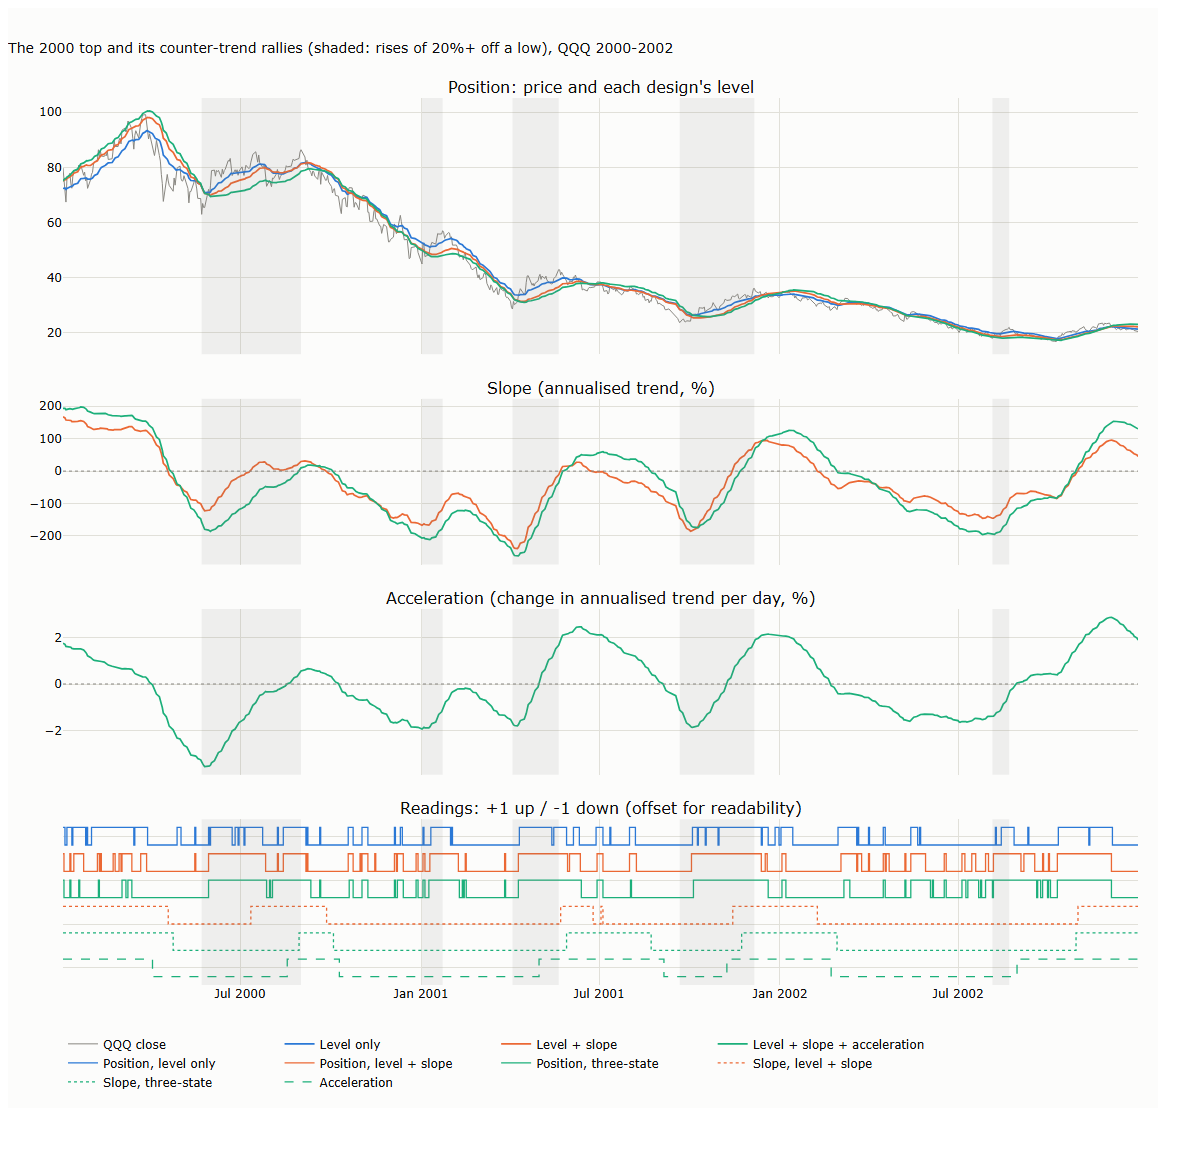

In [33]:
peak = dates.get_loc(pd.Timestamp("2000-03-10"))
for k in (1, 2, 3):
    a_ = run(y_qqq, k, R_MATCH[k], start_uncertainty=1.0)["states"]
    b_ = run(y_qqq, k, R_MATCH[k], start_uncertainty=1e-6)["states"]
    col = 1 if k > 1 else 0
    print(f"{NAMES[k]:30s}: from the 2000 peak on, starting choices change the level by at most {100 * np.abs(a_[peak:, 0] - b_[peak:, 0]).max():.3f}% "
          f"and the slope by at most {25200 * np.abs(a_[peak:, col] - b_[peak:, col]).max() if k > 1 else 0:.2f} %/yr")
seg = qqq.loc["2000-03-10":"2002-10-09"]
pts, mode = [], "down"
ext_i, ext_v = seg.index[0], seg.iloc[0]
for d, v in seg.items():
    if mode == "down":
        if v < ext_v: ext_v, ext_i = v, d
        elif v >= ext_v * 1.2: pts.append(("low", ext_i, ext_v)); mode, ext_v, ext_i = "up", v, d
    else:
        if v > ext_v: ext_v, ext_i = v, d
        elif v <= ext_v * 0.8: pts.append(("high", ext_i, ext_v)); mode, ext_v, ext_i = "down", v, d
rallies = [(pts[i][1], pts[i + 1][1], pts[i + 1][2] / pts[i][2] - 1) for i in range(len(pts) - 1) if pts[i][0] == "low" and pts[i + 1][0] == "high"]
bear = readings.loc["2000-03-10":"2002-10-09"]
rows = {}
for col in readings:
    per = []
    for a_, b_, r_ in rallies:
        w = readings[col].loc[a_:b_]
        hit = w[w > 0]
        per.append(f"{dates.get_loc(hit.index[0]) - dates.get_loc(a_)}/{len(w)}" if len(hit) else f"never/{len(w)}")
    rows[col] = {"sign changes": int((bear[col].diff().abs() > 0).sum()), "share of days pointing up (%)": round(100 * (bear[col] > 0).mean()),
                 "rallies followed": f"{sum(not p.startswith('never') for p in per)} of {len(per)}",
                 "days from each rally low until pointing up / rally length": ", ".join(per)}
print("Counter-trend rallies:", ", ".join(f"{a.date()} to {b.date()} (+{100 * r:.0f}%)" for a, b, r in rallies))
display(pd.DataFrame(rows).T)
states_figure("2000-01-01", "2002-12-31", "The 2000 top and its counter-trend rallies (shaded: rises of 20%+ off a low), QQQ 2000-2002",
              "c12_case_2000", shade=[(a, b) for a, b, _ in rallies])

**The 2020 V-shaped crash and recovery.** Two sharp turns about a month apart.

,days after the 2020-02-19 peak until pointing down,days after the 2020-03-23 low until pointing up,"sign changes, Feb-Jun 2020"
"Position, level only",3,3,6
"Position, level + slope",2,10,7
"Position, three-state",1,10,5
"Slope, level + slope",16,30,2
"Slope, three-state",18,40,2
Acceleration,13,39,2


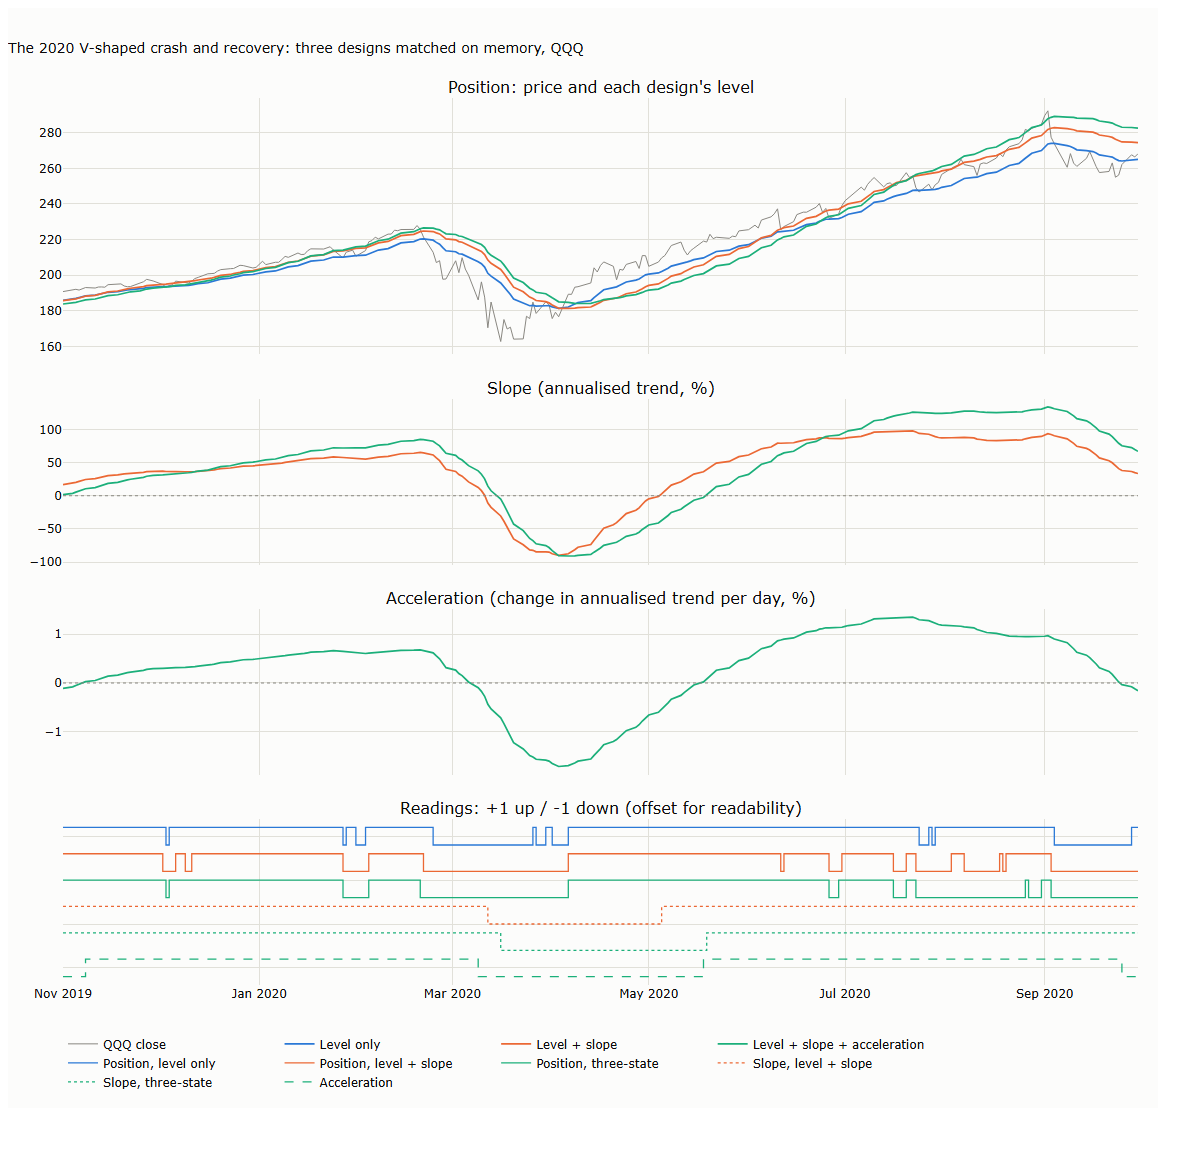

In [34]:
rows = {}
for col in readings:
    s = readings[col]

    def first(after, sign):
        w = s.loc[after:]
        hit = w[w == sign]
        return dates.get_loc(hit.index[0]) - dates.get_loc(w.index[0])

    rows[col] = {"days after the 2020-02-19 peak until pointing down": first("2020-02-19", -1),
                 "days after the 2020-03-23 low until pointing up": first("2020-03-23", 1),
                 "sign changes, Feb-Jun 2020": int((s.loc["2020-02-01":"2020-06-30"].diff().abs() > 0).sum())}
display(pd.DataFrame(rows).T)
states_figure("2019-11-01", "2020-09-30", "The 2020 V-shaped crash and recovery: three designs matched on memory, QQQ", "c13_case_2020")

## 14. A time-varying hedge ratio

The Kalman filter as a regression whose coefficients drift: QQQ's daily log return regressed on SPY's,
with the intercept and the hedge ratio (beta) as hidden states following random walks (the idea Chan,
2013, applies to an ETF pair). Compared with a rolling 63-day least-squares beta.

correlation of the Kalman beta with the rolling 63-day beta: 0.845
day-to-day variability (std of daily change): Kalman 0.0034, rolling 0.0193


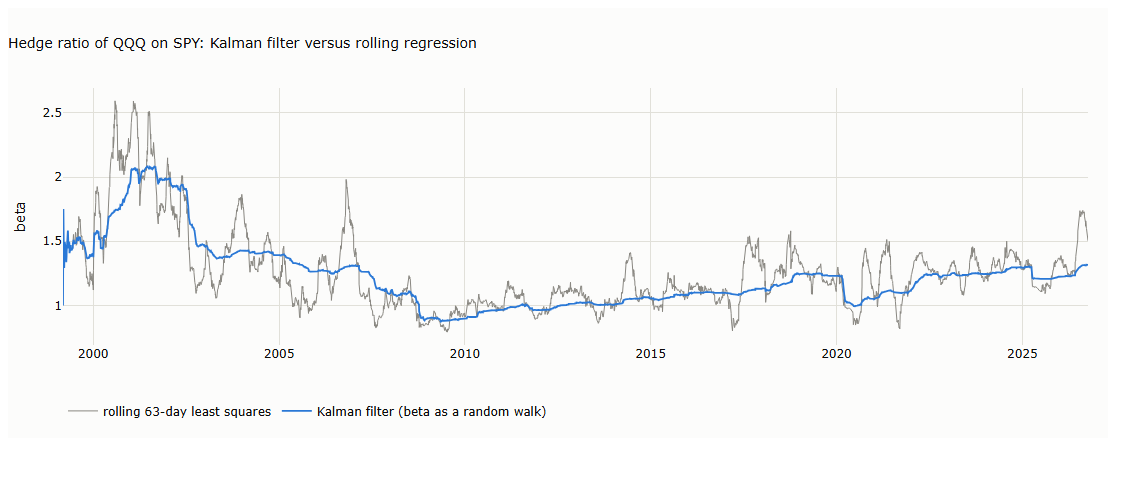

In [35]:
pair = pd.concat([np.log(C["QQQ"]).diff(), np.log(C["SPY"]).diff()], axis=1, keys=["QQQ", "SPY"]).dropna()
ya, xa = pair["QQQ"].to_numpy(), pair["SPY"].to_numpy()
state, P = np.array([0.0, 1.0]), np.eye(2)
Qb, Rb = np.diag([1e-8, 1e-5]), np.var(ya - xa)
betas = np.empty(len(ya))
for t in range(len(ya)):
    P = P + Qb
    h = np.array([1.0, xa[t]])
    S = h @ P @ h + Rb
    K = P @ h / S
    state = state + K * (ya[t] - h @ state)
    P = P - np.outer(K, h @ P)
    betas[t] = state[1]
kb = pd.Series(betas, index=pair.index)
roll = pair["QQQ"].rolling(63).cov(pair["SPY"]) / pair["SPY"].rolling(63).var()
print(f"correlation of the Kalman beta with the rolling 63-day beta: {kb.iloc[300:].corr(roll.iloc[300:]):.3f}")
print(f"day-to-day variability (std of daily change): Kalman {kb.diff().iloc[300:].std():.4f}, rolling {roll.diff().iloc[300:].std():.4f}")
fig = go.Figure()
fig.add_scatter(x=roll.index, y=roll, name="rolling 63-day least squares", mode="lines", line=dict(width=1, color=MUTED))
fig.add_scatter(x=kb.index, y=kb, name="Kalman filter (beta as a random walk)", mode="lines", line=dict(width=1.8, color=SERIES[0]))
fig.update_layout(title="Hedge ratio of QQQ on SPY: Kalman filter versus rolling regression", yaxis_title="beta",
                  height=430, width=1100, margin=dict(t=80, b=70), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "c14_hedge_ratio", FIG)
fig

## References

- Alizadeh, S., Brandt, M. and Diebold, F. (2002). Range-based estimation of stochastic volatility models. *Journal of Finance* 57(3), 1047–1091.
- Chan, E. (2013). *Algorithmic Trading: Winning Strategies and Their Rationale.* Wiley.
- Durbin, J. and Koopman, S.J. (2012). *Time Series Analysis by State Space Methods* (2nd ed.). Oxford University Press.
- Harvey, A. (1989). *Forecasting, Structural Time Series Models and the Kalman Filter.* Cambridge University Press.
- Julier, S. and Uhlmann, J. (1997). A new extension of the Kalman filter to nonlinear systems. *Proc. SPIE* 3068, 182–193.
- Julier, S. and Uhlmann, J. (2004). Unscented filtering and nonlinear estimation. *Proceedings of the IEEE* 92(3), 401–422.
- Kalman, R.E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering* 82(1), 35–45.
- Masreliez, C. and Martin, R.D. (1977). Robust Bayesian estimation for the linear model and robustifying the Kalman filter. *IEEE Transactions on Automatic Control* 22(3), 361–371.
- Mehra, R. (1970). On the identification of variances and adaptive Kalman filtering. *IEEE Transactions on Automatic Control* 15(2), 175–184.